# Clasificación de enfermedades en hojas de papa con ResNet-18

Caso práctico de Inteligencia Artificial II.

## 1. Verificación del entorno

Comprobamos las versiones de las herramientas y la ejecución en GPU.

In [2]:
# Importamos las herramientas
import sys
import torch
import torchvision

# Mostramos qué Python está ejecutando el notebook.
print("Python utilizado:", sys.executable)

# Consultamos las versiones de las bibliotecas.
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# Comprobamos si PyTorch puede acceder a la GPU mediante CUDA.
print("CUDA disponible:", torch.cuda.is_available())

Python utilizado: c:\Users\javip\OneDrive\Documentos\Trabajos\Resnet\.venv\Scripts\python.exe
PyTorch: 2.8.0+cu128
Torchvision: 0.23.0+cu128
CUDA disponible: True


In [4]:
# Creamos un tensor: un arreglo de números.
# device="cuda" indica que se guardará en la GPU.
x = torch.tensor([1.0, 2.0, 3.0], device="cuda")

# Multiplicamos cada elemento por dos usando la GPU.
resultado = x * 2

# Mostramos dónde está almacenado el tensor.
print("Dispositivo:", x.device)

# Copiamos el resultado a la memoria de la CPU para mostrarlo.
print("Resultado:", resultado.cpu())

Dispositivo: cuda:0
Resultado: tensor([2., 4., 6.])


## 2. Dataset: PlantVillage

Utilizamos imágenes RGB de hojas de papa de tres clases:
tizón temprano, tizón tardío y sana.

Primero comprobamos las cantidades disponibles por clase.

In [5]:
from pathlib import Path

# Indicamos dónde están las carpetas de imágenes.
ruta_datos = Path("data/raw")

# Comprobamos que la carpeta exista antes de leerla.
assert ruta_datos.exists(), "No se encontró la carpeta data/raw"

total = 0

# Cada subcarpeta representa una clase.
for carpeta in sorted(ruta_datos.iterdir()):
    if carpeta.is_dir():
        # Contamos únicamente archivos con extensiones de imagen.
        cantidad = sum(
            1 for archivo in carpeta.iterdir()
            if archivo.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        print(f"{carpeta.name}: {cantidad} imágenes")
        total += cantidad

print(f"\nTotal: {total} imágenes")

Potato___Early_blight: 1000 imágenes
Potato___healthy: 152 imágenes
Potato___Late_blight: 1000 imágenes

Total: 2152 imágenes


### 2.1. Exploración visual

Mostramos tres ejemplos por clase para observar las imágenes y
comprobar que podemos abrirlas.

Las imágenes pertenecen a PlantVillage y proceden del repositorio
spMohanty/PlantVillage-Dataset en GitHub.

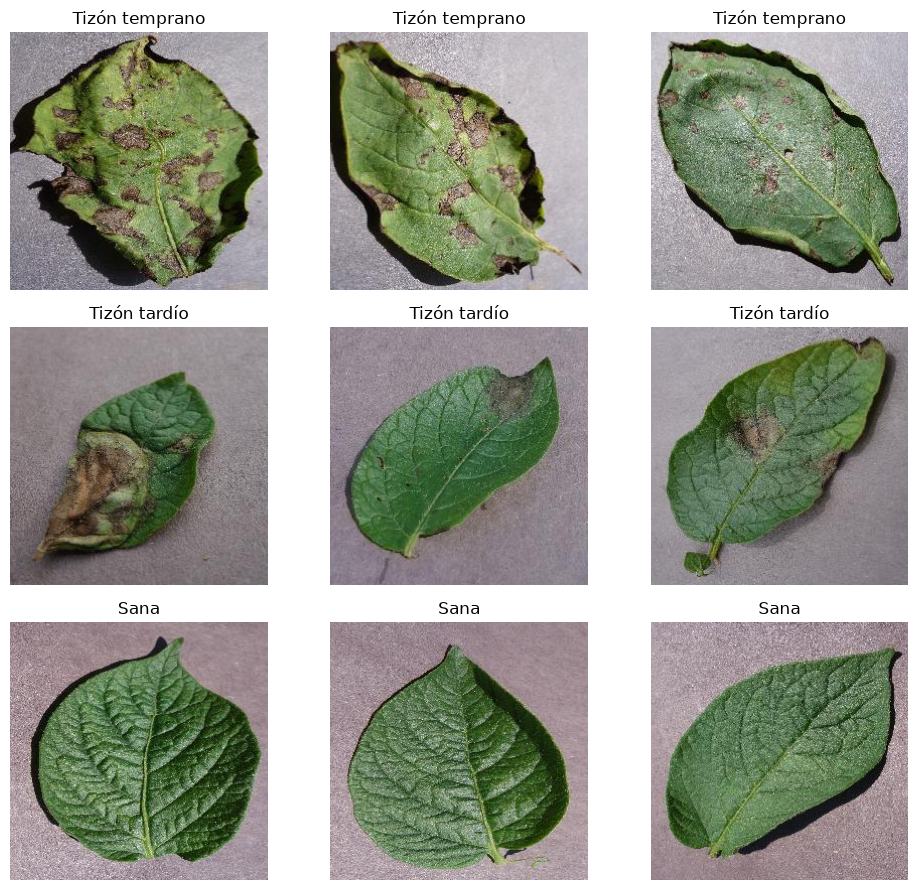

In [6]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Relacionamos los nombres de las carpetas con etiquetas en español.
clases = {
    "Potato___Early_blight": "Tizón temprano",
    "Potato___Late_blight": "Tizón tardío",
    "Potato___healthy": "Sana",
}

ruta_datos = Path("data/raw")

# Creamos una figura: una fila por clase y tres columnas de ejemplos.
fig, ejes = plt.subplots(3, 3, figsize=(10, 9))

for fila, (carpeta, etiqueta) in enumerate(clases.items()):
    # Ordenamos las imágenes para mostrar los mismos ejemplos al repetir.
    archivos = sorted(
        archivo for archivo in (ruta_datos / carpeta).iterdir()
        if archivo.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    for columna, ruta_imagen in enumerate(archivos[:3]):
        # Abrimos cada imagen y la mostramos en formato RGB.
        with Image.open(ruta_imagen) as imagen:
            ejes[fila, columna].imshow(imagen.convert("RGB"))

        ejes[fila, columna].set_title(etiqueta)
        ejes[fila, columna].axis("off")

# Ajustamos los espacios entre las imágenes.
plt.tight_layout()

# Guardamos la figura
ruta_resultados = Path("resultados")
ruta_resultados.mkdir(exist_ok=True)
fig.savefig(ruta_resultados / "ejemplos_dataset.png", dpi=150)

plt.show()

## 3. Preparación de los datos

### 3.1. Revisión de imágenes

Comprobamos que las imágenes puedan leerse y buscamos duplicados
exactos mediante SHA-256, una huella calculada a partir de cada archivo.

In [7]:
import hashlib

# Reunimos las rutas de las imágenes de las tres clases.
rutas_imagenes = []

for carpeta in clases:
    for ruta in sorted((ruta_datos / carpeta).iterdir()):
        if ruta.is_file() and ruta.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rutas_imagenes.append(ruta)

no_legibles = []
duplicados = []
huellas = {}

for ruta in rutas_imagenes:
    # Intentamos abrir y leer completamente la imagen.
    try:
        with Image.open(ruta) as imagen:
            imagen.load()
    except Exception as error:
        no_legibles.append((str(ruta), str(error)))
        continue

    # Calculamos la huella del contenido del archivo.
    huella = hashlib.sha256(ruta.read_bytes()).hexdigest()

    # Si la huella ya existe, encontramos un archivo idéntico.
    if huella in huellas:
        duplicados.append((str(huellas[huella]), str(ruta)))
    else:
        huellas[huella] = ruta

print("Archivos revisados:", len(rutas_imagenes))
print("Imágenes no legibles:", len(no_legibles))
print("Duplicados exactos:", len(duplicados))

Archivos revisados: 2152
Imágenes no legibles: 0
Duplicados exactos: 0


### 3.2. Identificación de hojas

Consultamos leaf-map.json para identificar las fotografías que
pertenecen a una misma hoja.

Todas las fotografías de una hoja deben quedar en la misma
partición: entrenamiento, validación o prueba.

In [8]:
import json

# Leemos el mapa que relaciona nombres de imágenes con hojas.
with open("data/leaf-map.json", encoding="utf-8") as archivo:
    mapa_hojas = json.load(archivo)

registros = []
sin_identificador = []

for ruta in rutas_imagenes:
    # Obtenemos la parte del nombre que utiliza el mapa.
    # stem elimina la extensión; lower convierte a minúsculas.
    nombre_base = ruta.stem.lower().split("___")[-1].strip()

    # Buscamos los identificadores asociados a ese nombre.
    coincidencias = mapa_hojas.get(nombre_base, [])

    # Conservamos los identificadores de la clase correspondiente.
    identificadores = {
        codigo for codigo in coincidencias
        if codigo.startswith(ruta.parent.name + ":::")
    }

    if len(identificadores) == 1:
        # Extraemos el identificador único de esa hoja.
        hoja = next(iter(identificadores))

        # Registramos la ruta, la clase y la hoja de cada imagen.
        registros.append({
            "ruta": str(ruta),
            "clase": ruta.parent.name,
            "hoja": hoja,
        })
    else:
        sin_identificador.append(str(ruta))

# Un conjunto elimina repeticiones y permite contar hojas distintas.
hojas_distintas = {registro["hoja"] for registro in registros}

print("Imágenes con identificador:", len(registros))
print("Imágenes sin identificador único:", len(sin_identificador))
print("Hojas distintas:", len(hojas_distintas))

# Detenemos el proceso si alguna imagen quedó sin identificar.
assert len(registros) == len(rutas_imagenes), "Falta revisar identificadores"

Imágenes con identificador: 2152
Imágenes sin identificador único: 0
Hojas distintas: 538


### 3.3. División de los datos por hojas y clases

Asignamos aproximadamente el 60 % de las hojas a entrenamiento,
el 20 % a validación y el 20 % a prueba.

Realizamos el reparto por clase y mantenemos juntas todas las
fotografías de una misma hoja. Fijamos la semilla 42 para que
la asignación pueda repetirse.

In [10]:
import random
from math import ceil

# Asociamos cada hoja con su clase.
clase_por_hoja = {
    registro["hoja"]: registro["clase"]
    for registro in registros
}

# Fijamos la semilla para repetir la misma división.
generador = random.Random(42)

# Creamos listas vacías para las tres particiones.
hojas_train = []
hojas_val = []
hojas_test = []

# Dividimos las hojas de cada clase por separado.
for carpeta in sorted(clases):
    hojas_clase = sorted(
        hoja for hoja, clase in clase_por_hoja.items()
        if clase == carpeta
    )

    # Mezclamos las hojas aleatoriamente.
    generador.shuffle(hojas_clase)

    # Reservamos aproximadamente un 20 % para cada evaluación.
    # Redondeamos hacia arriba porque necesitamos hojas completas.
    cantidad_reservada = ceil(len(hojas_clase) * 0.20)

    # Asignamos las primeras hojas a validación.
    hojas_val.extend(hojas_clase[:cantidad_reservada])

    # Asignamos las siguientes hojas a prueba.
    hojas_test.extend(
        hojas_clase[cantidad_reservada:2 * cantidad_reservada]
    )

    # Asignamos las restantes a entrenamiento.
    hojas_train.extend(hojas_clase[2 * cantidad_reservada:])

# Comprobamos que ninguna hoja aparezca en dos particiones.
assert set(hojas_train).isdisjoint(hojas_val)
assert set(hojas_train).isdisjoint(hojas_test)
assert set(hojas_val).isdisjoint(hojas_test)

# Comprobamos que todas las hojas estén asignadas.
assert (
    set(hojas_train) | set(hojas_val) | set(hojas_test)
) == set(clase_por_hoja)

# Estas impresiones están fuera del ciclo y se ejecutan una sola vez.
print("Hojas de entrenamiento:", len(hojas_train))
print("Hojas de validación:", len(hojas_val))
print("Hojas de prueba:", len(hojas_test))

Hojas de entrenamiento: 322
Hojas de validación: 108
Hojas de prueba: 108


### 3.4. Asignación de imágenes y guardado de las particiones

Cada imagen recibe la partición asignada a su hoja.

Guardamos una tabla CSV con la ruta, clase, identificador de hoja,
partición y huella SHA-256 de cada imagen. Utilizaremos esta misma
asignación en todos los entrenamientos.

In [11]:
# Relacionamos cada partición con sus hojas.
particiones_hojas = {
    "entrenamiento": hojas_train,
    "validacion": hojas_val,
    "prueba": hojas_test,
}

# Creamos un diccionario para consultar la partición de cada hoja.
particion_por_hoja = {}

for nombre, lista_hojas in particiones_hojas.items():
    for hoja in lista_hojas:
        particion_por_hoja[hoja] = nombre

# Recuperamos las huellas calculadas durante la revisión de archivos.
# as_posix utiliza barras "/" para facilitar el uso en otros sistemas.
huella_por_ruta = {
    ruta.as_posix(): huella
    for huella, ruta in huellas.items()
}

# Asignamos a cada fotografía la partición de su hoja.
for registro in registros:
    registro["ruta"] = Path(registro["ruta"]).as_posix()
    registro["particion"] = particion_por_hoja[registro["hoja"]]
    registro["sha256"] = huella_por_ruta[registro["ruta"]]

# Contamos las imágenes asignadas a cada partición.
for nombre in particiones_hojas:
    cantidad = sum(
        registro["particion"] == nombre
        for registro in registros
    )
    print(f"{nombre}: {cantidad} imágenes")

entrenamiento: 1288 imágenes
validacion: 432 imágenes
prueba: 432 imágenes


In [12]:
import csv

# Indicamos dónde guardaremos la tabla de particiones.
ruta_csv = Path("resultados/particiones.csv")
ruta_csv.parent.mkdir(exist_ok=True)

# Escribimos una fila por imagen.
with ruta_csv.open("w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(
        archivo,
        fieldnames=["ruta", "clase", "hoja", "particion", "sha256"],
    )
    escritor.writeheader()
    escritor.writerows(registros)

print("División guardada en:", ruta_csv)

División guardada en: resultados\particiones.csv


### 3.5. Transformación de las imágenes

Preparamos imágenes de 224 × 224 píxeles y tres canales RGB.

Solo en entrenamiento aplicamos aumentos moderados: recortes,
volteos horizontales, rotaciones y pequeñas variaciones de color.

Validación y prueba utilizan redimensionado y recorte central.
En todas las particiones aplicamos la normalización de ImageNet.

In [13]:
from torchvision import transforms
from torchvision.transforms import InterpolationMode

# Valores de normalización utilizados con los pesos de ImageNet.
media = [0.485, 0.456, 0.406]
desviacion = [0.229, 0.224, 0.225]

# Transformaciones aleatorias: únicamente para entrenamiento.
transformacion_train = transforms.Compose([
    # Recortamos una parte amplia y ajustamos su tamaño a 224 × 224.
    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0),
        interpolation=InterpolationMode.BILINEAR,
    ),

    # Aplicamos variaciones moderadas.
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(
        15, interpolation=InterpolationMode.BILINEAR
    ),
    transforms.ColorJitter(
        brightness=0.1, contrast=0.1, saturation=0.1
    ),

    # Convertimos la imagen en un tensor y normalizamos sus valores.
    transforms.ToTensor(),
    transforms.Normalize(mean=media, std=desviacion),
])

# Procesamiento fijo: para validación, prueba y predicciones.
transformacion_eval = transforms.Compose([
    # Redimensionamos el lado menor a 256 y recortamos el centro.
    transforms.Resize(256, interpolation=InterpolationMode.BILINEAR),
    transforms.CenterCrop(224),

    transforms.ToTensor(),
    transforms.Normalize(mean=media, std=desviacion),
])

In [14]:
# Elegimos una imagen perteneciente a entrenamiento.
ruta_ejemplo = next(
    registro["ruta"] for registro in registros
    if registro["particion"] == "entrenamiento"
)

# Aplicamos el procesamiento fijo para comprobar las dimensiones.
with Image.open(ruta_ejemplo) as imagen:
    tensor_ejemplo = transformacion_eval(imagen.convert("RGB"))

print("Dimensiones:", tuple(tensor_ejemplo.shape))
print("Tipo de datos:", tensor_ejemplo.dtype)

Dimensiones: (3, 224, 224)
Tipo de datos: torch.float32


### 3.6. Preparación de los conjuntos para PyTorch

Creamos un Dataset que abre cada imagen, aplica las transformaciones
y devuelve su etiqueta numérica:

- 0: tizón temprano.
- 1: tizón tardío.
- 2: sana.

Utilizamos las particiones guardadas en el archivo CSV.

In [15]:
from torch.utils.data import Dataset

# Asignamos un número a cada clase.
clase_a_indice = {
    "Potato___Early_blight": 0,
    "Potato___Late_blight": 1,
    "Potato___healthy": 2,
}

class DatasetPapa(Dataset):
    # Guardamos los registros y la transformación que utilizaremos.
    def __init__(self, registros, transformacion):
        self.registros = registros
        self.transformacion = transformacion

    # Indicamos cuántas imágenes contiene este conjunto.
    def __len__(self):
        return len(self.registros)

    # Obtenemos una imagen y su etiqueta mediante su posición.
    def __getitem__(self, indice):
        registro = self.registros[indice]

        # Abrimos la imagen y aplicamos su transformación.
        with Image.open(registro["ruta"]) as imagen:
            imagen_tensor = self.transformacion(imagen.convert("RGB"))

        # Convertimos el nombre de la clase en su número.
        etiqueta = clase_a_indice[registro["clase"]]

        return imagen_tensor, etiqueta

In [16]:
import csv

# Leemos la división que guardamos anteriormente.
with open("resultados/particiones.csv", newline="", encoding="utf-8") as archivo:
    registros_guardados = list(csv.DictReader(archivo))

# Separamos los registros según su partición.
datos_train = [
    registro for registro in registros_guardados
    if registro["particion"] == "entrenamiento"
]

datos_val = [
    registro for registro in registros_guardados
    if registro["particion"] == "validacion"
]

datos_test = [
    registro for registro in registros_guardados
    if registro["particion"] == "prueba"
]

# Entrenamiento utiliza aumentos aleatorios.
dataset_train = DatasetPapa(datos_train, transformacion_train)

# Validación y prueba utilizan el procesamiento fijo.
dataset_val = DatasetPapa(datos_val, transformacion_eval)
dataset_test = DatasetPapa(datos_test, transformacion_eval)

print("Imágenes de entrenamiento:", len(dataset_train))
print("Imágenes de validación:", len(dataset_val))
print("Imágenes de prueba:", len(dataset_test))

Imágenes de entrenamiento: 1288
Imágenes de validación: 432
Imágenes de prueba: 432


### 3.7. Carga de datos por lotes

Utilizamos lotes de 16 imágenes.

En entrenamiento mezclamos el orden de las imágenes.
En validación y prueba mantenemos un orden fijo.

In [17]:
from torch.utils.data import DataLoader

def crear_cargadores(semilla=0):
    # Controlamos la mezcla de imágenes con una semilla fija.
    generador = torch.Generator().manual_seed(semilla)

    # Entrenamiento: mezclamos las imágenes.
    cargador_train = DataLoader(
        dataset_train,
        batch_size=16,
        shuffle=True,
        generator=generador,
        num_workers=0,
        pin_memory=True,
    )

    # Validación: conservamos el orden de las imágenes.
    cargador_val = DataLoader(
        dataset_val,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )

    # Prueba: conservamos el orden de las imágenes.
    cargador_test = DataLoader(
        dataset_test,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )

    return cargador_train, cargador_val, cargador_test

# Creamos los tres cargadores.
cargador_train, cargador_val, cargador_test = crear_cargadores()

In [18]:
# Obtenemos un lote de entrenamiento.
imagenes_lote, etiquetas_lote = next(iter(cargador_train))

print("Dimensiones de las imágenes:", tuple(imagenes_lote.shape))
print("Dimensiones de las etiquetas:", tuple(etiquetas_lote.shape))
print("Tipo de etiquetas:", etiquetas_lote.dtype)

Dimensiones de las imágenes: (16, 3, 224, 224)
Dimensiones de las etiquetas: (16,)
Tipo de etiquetas: torch.int64


## 4. Implementación de ResNet-18

Adaptamos la capa final de ResNet-18 para clasificar:
tizón temprano, tizón tardío y sana.

Comparamos entrenamiento desde cero, extracción de características
y ajuste fino.

In [19]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Seleccionamos el dispositivo donde ejecutaremos el modelo.
dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def crear_modelo(estrategia):
    # Comprobamos que la estrategia sea válida.
    estrategias = {"scratch", "feature_extraction", "finetune"}

    if estrategia not in estrategias:
        raise ValueError("Estrategia no reconocida")

    # scratch utiliza pesos aleatorios.
    # Las otras estrategias utilizan pesos de ImageNet.
    pesos = (
        None if estrategia == "scratch"
        else ResNet18_Weights.IMAGENET1K_V1
    )

    modelo = resnet18(weights=pesos)

    # Adaptamos la capa final a nuestras tres clases.
    modelo.fc = nn.Linear(modelo.fc.in_features, 3)

    if estrategia == "feature_extraction":
        # Congelamos los parámetros de toda la red.
        for parametro in modelo.parameters():
            parametro.requires_grad = False

        # Permitimos entrenar únicamente la capa final.
        for parametro in modelo.fc.parameters():
            parametro.requires_grad = True

        # Conservamos las estadísticas del cuerpo preentrenado.
        modelo.eval()
        modelo.fc.train()

    return modelo

In [20]:
# Creamos un modelo con pesos aleatorios.
modelo_inspeccion = crear_modelo("scratch").to(dispositivo)
modelo_inspeccion.eval()

# Comprobamos la salida sin calcular gradientes.
with torch.no_grad():
    salidas = modelo_inspeccion(imagenes_lote.to(dispositivo))

print("Capa final:", modelo_inspeccion.fc)
print("Dimensiones de salida:", tuple(salidas.shape))

Capa final: Linear(in_features=512, out_features=3, bias=True)
Dimensiones de salida: (16, 3)


### Resumen de la arquitectura ResNet-18

Mostramos las capas, las dimensiones de salida y la cantidad de parámetros
de ResNet-18 adaptada a las tres categorías del dataset.

In [28]:
from torchinfo import summary

# Inspeccionamos el modelo con una imagen RGB de 224 × 224.
# El modo evaluación evita modificar las estadísticas de BatchNorm.
resumen_modelo = summary(
    modelo_inspeccion,
    input_size=(1, 3, 224, 224),
    device=dispositivo,
    mode="eval",
    depth=2,
    col_names=["output_size", "num_params", "trainable"],
    row_settings=["var_names"],
    verbose=0,
)

print(resumen_modelo)

Layer (type (var_name))                  Output Shape              Param #                   Trainable
ResNet (ResNet)                          [1, 3]                    --                        True
├─Conv2d (conv1)                         [1, 64, 112, 112]         9,408                     True
├─BatchNorm2d (bn1)                      [1, 64, 112, 112]         128                       True
├─ReLU (relu)                            [1, 64, 112, 112]         --                        --
├─MaxPool2d (maxpool)                    [1, 64, 56, 56]           --                        --
├─Sequential (layer1)                    [1, 64, 56, 56]           --                        True
│    └─BasicBlock (0)                    [1, 64, 56, 56]           73,984                    True
│    └─BasicBlock (1)                    [1, 64, 56, 56]           73,984                    True
├─Sequential (layer2)                    [1, 128, 28, 28]          --                        True
│    └─BasicBlock (

### 4.1. Función de pérdida y ponderación de clases

Utilizamos CrossEntropyLoss para medir el error de clasificación.

Calculamos pesos inversamente proporcionales a la cantidad de imágenes
de entrenamiento de cada clase. Así, los errores de las clases menos
representadas reciben mayor peso.

In [21]:
# Contamos las imágenes de entrenamiento según su etiqueta numérica.
cantidades = torch.zeros(3, dtype=torch.float32)

for registro in datos_train:
    indice = clase_a_indice[registro["clase"]]
    cantidades[indice] += 1

# Comprobamos que todas las clases estén representadas.
assert torch.all(cantidades > 0), "Falta una clase en entrenamiento"

# Calculamos los pesos: total / (número de clases × cantidad de la clase).
pesos_clase = cantidades.sum() / (3 * cantidades)

# Creamos la función de pérdida con los pesos en el dispositivo del modelo.
criterio = nn.CrossEntropyLoss(
    weight=pesos_clase.to(dispositivo)
)

print("Pesos por clase:", pesos_clase)

# Calculamos el error del lote que pasó por el modelo.
perdida_ejemplo = criterio(
    salidas,
    etiquetas_lote.to(dispositivo),
)

print("Pérdida del lote:", perdida_ejemplo.item())

Pesos por clase: tensor([0.7156, 0.7156, 4.8788])
Pérdida del lote: 1.4608293771743774


### 4.2. Configuración del optimizador

Utilizamos Adam con tasas de aprendizaje según la estrategia.

En finetune aplicamos una tasa menor al cuerpo preentrenado que
a la nueva capa final.

Utilizamos weight_decay=0.0001 como regularización en las tres estrategias.

In [22]:
from torch.optim import Adam

def crear_optimizador(modelo, estrategia):
    # Comprobamos que la estrategia sea válida.
    estrategias = {"scratch", "feature_extraction", "finetune"}

    if estrategia not in estrategias:
        raise ValueError("Estrategia no reconocida")

    if estrategia == "finetune":
        # Separamos los parámetros del cuerpo y de la capa final.
        parametros_cuerpo = [
            parametro
            for nombre, parametro in modelo.named_parameters()
            if not nombre.startswith("fc.")
        ]

        # Asignamos una tasa de aprendizaje a cada grupo.
        return Adam(
            [
                {"params": parametros_cuerpo, "lr": 1e-5},
                {"params": modelo.fc.parameters(), "lr": 1e-4},
            ],
            weight_decay=1e-4,
        )

    # En las otras estrategias seleccionamos los parámetros entrenables.
    parametros_entrenables = [
        parametro for parametro in modelo.parameters()
        if parametro.requires_grad
    ]

    return Adam(
        parametros_entrenables,
        lr=1e-3,
        weight_decay=1e-4,
    )

In [23]:
# Configuramos Adam para el modelo scratch que inspeccionamos.
optimizador_inspeccion = crear_optimizador(
    modelo_inspeccion, "scratch"
)

print("Optimizador:", type(optimizador_inspeccion).__name__)
print("Tasa de aprendizaje:", optimizador_inspeccion.param_groups[0]["lr"])
print("Regularización:", optimizador_inspeccion.param_groups[0]["weight_decay"])

Optimizador: Adam
Tasa de aprendizaje: 0.001
Regularización: 0.0001


## 5. Entrenamiento

### 5.1. Comprobación de una actualización

Realizamos una actualización con un lote de entrenamiento:

1. Limpiamos los gradientes anteriores.
2. Calculamos las predicciones y la pérdida.
3. Calculamos los gradientes mediante backpropagation.
4. Actualizamos los pesos con Adam.

Los experimentos finales comenzarán con modelos nuevos y semillas fijadas.

In [24]:
# Activamos el modo entrenamiento del modelo scratch.
modelo_inspeccion.train()

# Movemos las imágenes y sus etiquetas a la GPU.
imagenes_gpu = imagenes_lote.to(dispositivo)
etiquetas_gpu = etiquetas_lote.to(dispositivo)

# 1. Limpiamos los gradientes anteriores.
optimizador_inspeccion.zero_grad(set_to_none=True)

# 2. Calculamos las predicciones y la pérdida.
salidas_entrenamiento = modelo_inspeccion(imagenes_gpu)
perdida_entrenamiento = criterio(
    salidas_entrenamiento, etiquetas_gpu
)

# 3. Calculamos los gradientes mediante backpropagation.
perdida_entrenamiento.backward()

# 4. Actualizamos los pesos utilizando Adam.
optimizador_inspeccion.step()

print("Imágenes procesadas:", imagenes_gpu.shape[0])
print("Pérdida del lote:", perdida_entrenamiento.item())
print("Dispositivo utilizado:", imagenes_gpu.device)

Imágenes procesadas: 16
Pérdida del lote: 1.08957040309906
Dispositivo utilizado: cuda:0


### 5.2. Configuración de los experimentos

Comparamos scratch, feature_extraction y finetune utilizando
las semillas 0, 1 y 2.

El máximo inicial será de 20 épocas, con parada después de cinco
épocas sin mejorar F1 macro de validación.

Todas las ejecuciones utilizarán las mismas particiones.

In [25]:
import random
import numpy as np

# Definimos las condiciones comunes.
config_entrenamiento = {
    "strategies": ["scratch", "feature_extraction", "finetune"],
    "seeds": [0, 1, 2],
    "max_epochs": 20,
    "patience": 5,
    "batch_size": 16,
    "amp": True,
}

def fijar_semilla(semilla):
    # Controlamos la aleatoriedad de Python y NumPy.
    random.seed(semilla)
    np.random.seed(semilla)

    # Controlamos la aleatoriedad de PyTorch.
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)

    # Favorecemos la reproducibilidad de las convoluciones.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

# Comprobamos que el tamaño de lote coincida con nuestros cargadores.
assert cargador_train.batch_size == config_entrenamiento["batch_size"]

# Calculamos el número de combinaciones.
cantidad_experimentos = (
    len(config_entrenamiento["strategies"])
    * len(config_entrenamiento["seeds"])
)

print("Entrenamientos previstos:", cantidad_experimentos)
print("Máximo de épocas:", config_entrenamiento["max_epochs"])
print("Paciencia:", config_entrenamiento["patience"])

Entrenamientos previstos: 9
Máximo de épocas: 20
Paciencia: 5


### 5.3. Función de entrenamiento y validación por época

Esta función recorre todos los lotes de una partición y calcula la pérdida,
la exactitud y el F1 macro.

Durante el entrenamiento actualiza los parámetros del modelo. Durante la
validación únicamente calcula las métricas.

En extracción de características, el cuerpo de ResNet permanece congelado,
incluidas las estadísticas de BatchNorm.

In [26]:
from sklearn.metrics import accuracy_score, f1_score


def ejecutar_epoca(
    modelo,
    cargador,
    estrategia,
    optimizador=None,
    escalador=None,
):
    # Si recibimos un optimizador, estamos entrenando.
    entrenando = optimizador is not None

    if entrenando and escalador is None:
        raise ValueError("El entrenamiento requiere un escalador.")

    # Activamos entrenamiento o evaluación según corresponda.
    modelo.train(entrenando)

    if entrenando and estrategia == "feature_extraction":
        # Congelamos también las estadísticas de BatchNorm del cuerpo.
        modelo.eval()

        # Únicamente la capa final permanece en modo entrenamiento.
        modelo.fc.train()

    suma_perdidas = 0.0
    peso_total = 0.0
    etiquetas_reales = []
    etiquetas_predichas = []

    usar_amp = (
        config_entrenamiento["amp"]
        and dispositivo.type == "cuda"
    )

    # En validación no necesitamos calcular gradientes.
    with torch.set_grad_enabled(entrenando):
        for imagenes, etiquetas in cargador:
            imagenes = imagenes.to(dispositivo, non_blocking=True)
            etiquetas = etiquetas.to(dispositivo, non_blocking=True)

            if entrenando:
                optimizador.zero_grad(set_to_none=True)

            # La precisión mixta reduce el uso de memoria en la GPU.
            with torch.autocast(
                device_type=dispositivo.type,
                dtype=torch.float16,
                enabled=usar_amp,
            ):
                salidas = modelo(imagenes)
                perdida = criterio(salidas, etiquetas)

            if not torch.isfinite(perdida).item():
                raise RuntimeError("Se obtuvo una pérdida no finita.")

            if entrenando:
                # Calculamos gradientes y actualizamos los parámetros.
                escalador.scale(perdida).backward()
                escalador.step(optimizador)
                escalador.update()

            # Agregamos la pérdida respetando la ponderación por clase.
            peso_lote = criterio.weight[etiquetas].sum().item()
            suma_perdidas += perdida.item() * peso_lote
            peso_total += peso_lote

            # La salida de mayor valor determina la clase predicha.
            predicciones = salidas.detach().argmax(dim=1)

            etiquetas_reales.extend(etiquetas.detach().cpu().tolist())
            etiquetas_predichas.extend(predicciones.cpu().tolist())

    return {
        "loss": suma_perdidas / peso_total,
        "accuracy": float(
            accuracy_score(etiquetas_reales, etiquetas_predichas)
        ),
        "f1_macro": float(
            f1_score(
                etiquetas_reales,
                etiquetas_predichas,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0,
            )
        ),
    }


print("Función de época preparada.")

Función de época preparada.


### 5.4. Prueba del ciclo completo

Ejecutamos una época de entrenamiento y validación con ResNet-18 desde cero.

Esta prueba permite verificar el procesamiento completo de los datos,
el cálculo de las métricas y el guardado del modelo. Sus resultados no
forman parte de la comparación experimental final.

La partición de prueba permanece reservada.

In [27]:
from time import perf_counter

# Creamos un modelo nuevo para esta prueba.
fijar_semilla(0)

modelo_piloto = crear_modelo("scratch").to(dispositivo)
optimizador_piloto = crear_optimizador(modelo_piloto, "scratch")

# El escalador se conserva durante todo el entrenamiento del modelo.
usar_amp = (
    config_entrenamiento["amp"]
    and dispositivo.type == "cuda"
)

escalador_piloto = torch.amp.GradScaler(
    "cuda",
    enabled=usar_amp,
)

# Creamos cargadores nuevos para comenzar con la semilla indicada.
cargador_piloto_train, cargador_piloto_val, _ = crear_cargadores(
    semilla=0
)

if dispositivo.type == "cuda":
    torch.cuda.synchronize()

inicio = perf_counter()

# Recorremos una vez todas las imágenes de entrenamiento.
metricas_train = ejecutar_epoca(
    modelo=modelo_piloto,
    cargador=cargador_piloto_train,
    estrategia="scratch",
    optimizador=optimizador_piloto,
    escalador=escalador_piloto,
)

# Evaluamos en validación sin actualizar los parámetros.
metricas_val = ejecutar_epoca(
    modelo=modelo_piloto,
    cargador=cargador_piloto_val,
    estrategia="scratch",
)

if dispositivo.type == "cuda":
    torch.cuda.synchronize()

duracion = perf_counter() - inicio

# Guardamos los resultados de esta prueba en un archivo pequeño.
registro_piloto = {
    "strategy": "scratch",
    "seed": 0,
    "epoch": 1,
    "train_loss": metricas_train["loss"],
    "train_accuracy": metricas_train["accuracy"],
    "train_f1_macro": metricas_train["f1_macro"],
    "val_loss": metricas_val["loss"],
    "val_accuracy": metricas_val["accuracy"],
    "val_f1_macro": metricas_val["f1_macro"],
    "duration_seconds": duracion,
}

ruta_metricas = Path("resultados/piloto.csv")
ruta_metricas.parent.mkdir(parents=True, exist_ok=True)

with ruta_metricas.open("w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(
        archivo,
        fieldnames=list(registro_piloto),
    )
    escritor.writeheader()
    escritor.writerow(registro_piloto)

# Este archivo permite volver a cargar los pesos del modelo piloto.
ruta_modelo = Path("checkpoints/pilot/scratch_seed0.pt")
ruta_modelo.parent.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": modelo_piloto.state_dict(),
        "strategy": "scratch",
        "seed": 0,
        "epoch": 1,
        "class_to_idx": clase_a_indice,
        "metrics": registro_piloto,
    },
    ruta_modelo,
)

print(f"Pérdida de entrenamiento: {metricas_train['loss']:.4f}")
print(f"F1 macro de entrenamiento: {metricas_train['f1_macro']:.4f}")
print(f"Pérdida de validación: {metricas_val['loss']:.4f}")
print(f"F1 macro de validación: {metricas_val['f1_macro']:.4f}")
print(f"Tiempo: {duracion:.1f} segundos")
print(f"Modelo guardado en: {ruta_modelo}")
print(f"Métricas guardadas en: {ruta_metricas}")

Pérdida de entrenamiento: 0.7132
F1 macro de entrenamiento: 0.6643
Pérdida de validación: 1.6956
F1 macro de validación: 0.4748
Tiempo: 23.9 segundos
Modelo guardado en: checkpoints\pilot\scratch_seed0.pt
Métricas guardadas en: resultados\piloto.csv


### 5.5. Verificación del modelo guardado

Recargamos los pesos en una nueva instancia de ResNet-18 y comprobamos
que produce las mismas salidas que el modelo piloto sobre un lote
de validación.

In [29]:
# Leemos el archivo guardado durante la prueba piloto.
checkpoint_piloto = torch.load(
    ruta_modelo,
    map_location="cpu",
    weights_only=True,
)

# Creamos otra instancia y recuperamos los parámetros guardados.
modelo_recargado = crear_modelo(
    checkpoint_piloto["strategy"]
).to(dispositivo)

modelo_recargado.load_state_dict(
    checkpoint_piloto["model_state_dict"]
)

# Ambos modelos deben estar en modo evaluación.
modelo_piloto.eval()
modelo_recargado.eval()

imagenes_comparacion, _ = next(iter(cargador_piloto_val))
imagenes_comparacion = imagenes_comparacion.to(dispositivo)

with torch.no_grad():
    salidas_originales = modelo_piloto(imagenes_comparacion)
    salidas_recargadas = modelo_recargado(imagenes_comparacion)

# La comprobación genera un error si las salidas no coinciden
# dentro de la tolerancia numérica.
torch.testing.assert_close(
    salidas_originales,
    salidas_recargadas,
)

print("Modelo recargado correctamente.")
print("Las salidas coinciden con las del modelo piloto.")

Modelo recargado correctamente.
Las salidas coinciden con las del modelo piloto.


### 5.6. Preparación del guardado y la reanudación

Durante el entrenamiento conservaremos el mejor modelo según el F1 macro
de validación y el último estado completo de cada ejecución.

Para reanudar también necesitamos recuperar el optimizador, el escalador
de precisión mixta, el historial y los estados de los generadores aleatorios.

In [30]:
def capturar_estado_aleatorio(cargador):
    # NumPy devuelve un arreglo que convertimos en una lista
    # para facilitar su almacenamiento en el checkpoint.
    estado_numpy = np.random.get_state()

    return {
        "python": random.getstate(),
        "numpy": (
            estado_numpy[0],
            estado_numpy[1].tolist(),
            estado_numpy[2],
            estado_numpy[3],
            estado_numpy[4],
        ),
        "torch": torch.get_rng_state(),
        "cuda": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else []
        ),
        "loader": cargador.generator.get_state(),
    }


def restaurar_estado_aleatorio(estado, cargador):
    # Recuperamos los generadores utilizados por el entrenamiento.
    random.setstate(estado["python"])

    estado_numpy = estado["numpy"]

    np.random.set_state(
        (
            estado_numpy[0],
            np.array(estado_numpy[1], dtype=np.uint32),
            estado_numpy[2],
            estado_numpy[3],
            estado_numpy[4],
        )
    )

    torch.set_rng_state(estado["torch"])

    if estado["cuda"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(estado["cuda"])

    cargador.generator.set_state(estado["loader"])


def guardar_checkpoint(contenido, ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)

    # Primero completamos un archivo temporal.
    # Después reemplazamos el checkpoint anterior.
    ruta_temporal = ruta.with_suffix(ruta.suffix + ".tmp")

    torch.save(contenido, ruta_temporal)
    ruta_temporal.replace(ruta)


print("Funciones de guardado y reanudación preparadas.")

Funciones de guardado y reanudación preparadas.


### 5.7. Entrenamiento con parada temprana

Cada ejecución comienza con una semilla y un modelo nuevo.

Seleccionamos el mejor modelo mediante el F1 macro de validación.
El entrenamiento termina al completar el máximo de épocas o acumular
cinco épocas consecutivas sin mejorar.

Guardamos las métricas por época, la configuración, el mejor modelo
y el último estado completo para poder reanudar.

In [31]:
import hashlib
import json
from time import perf_counter


def guardar_historial(historial, ruta):
    # Exportamos las métricas para generar después tablas y curvas.
    with Path(ruta).open("w", newline="", encoding="utf-8") as archivo:
        escritor = csv.DictWriter(
            archivo,
            fieldnames=list(historial[0]),
        )
        escritor.writeheader()
        escritor.writerows(historial)


def entrenar_modelo(estrategia, semilla, grupo="final"):
    # Cada combinación tendrá sus propias carpetas.
    nombre = f"{estrategia}_seed{semilla}"
    carpeta_modelos = Path("checkpoints") / grupo / nombre
    carpeta_resultados = Path("resultados") / grupo / nombre

    carpeta_modelos.mkdir(parents=True, exist_ok=True)
    carpeta_resultados.mkdir(parents=True, exist_ok=True)

    ruta_last = carpeta_modelos / "last.pt"
    ruta_best = carpeta_modelos / "best.pt"
    ruta_historial = carpeta_resultados / "history.csv"

    # Inicializamos nuevamente el modelo y los cargadores.
    fijar_semilla(semilla)
    modelo = crear_modelo(estrategia).to(dispositivo)
    optimizador = crear_optimizador(modelo, estrategia)
    train_loader, val_loader, _ = crear_cargadores(semilla)

    assert train_loader.batch_size == config_entrenamiento["batch_size"]

    usar_amp = (
        config_entrenamiento["amp"]
        and dispositivo.type == "cuda"
    )
    escalador = torch.amp.GradScaler("cuda", enabled=usar_amp)

    # Registramos las condiciones reales de esta ejecución.
    configuracion = {
        **config_entrenamiento,
        "strategy": estrategia,
        "seed": semilla,
        "classes": dict(clase_a_indice),
        "class_weights": criterio.weight.detach().cpu().tolist(),
        "optimizer": "Adam",
        "learning_rates": [
            grupo_parametros["lr"]
            for grupo_parametros in optimizador.param_groups
        ],
        "weight_decay": 1e-4,
        "train_transform": str(transformacion_train),
        "eval_transform": str(transformacion_eval),
        "split_sha256": hashlib.sha256(
            Path("resultados/particiones.csv").read_bytes()
        ).hexdigest(),
        "torch_version": str(torch.__version__),
        "torchvision_version": str(torchvision.__version__),
        "device": str(dispositivo),
        "amp_enabled": usar_amp,
    }

    historial = []
    mejor_f1 = -1.0
    mejor_epoca = 0
    mejor_estado = None
    sin_mejora = 0
    primera_epoca = 1

    # Si ya existe un estado completo, continuamos desde él.
    if ruta_last.exists():
        checkpoint = torch.load(
            ruta_last,
            map_location="cpu",
            weights_only=True,
        )

        if checkpoint["config"] != configuracion:
            raise ValueError(
                "La configuración o las particiones cambiaron. "
                "Utiliza otro grupo para un experimento nuevo."
            )

        modelo.load_state_dict(checkpoint["model_state_dict"])
        optimizador.load_state_dict(checkpoint["optimizer_state_dict"])
        escalador.load_state_dict(checkpoint["scaler_state_dict"])

        historial = checkpoint["history"]
        mejor_f1 = checkpoint["best_val_f1"]
        mejor_epoca = checkpoint["best_epoch"]
        mejor_estado = checkpoint["best_model_state_dict"]
        sin_mejora = checkpoint["epochs_without_improvement"]
        primera_epoca = checkpoint["epoch"] + 1

        restaurar_estado_aleatorio(
            checkpoint["random_state"],
            train_loader,
        )

        print(f"Estado recuperado: {nombre}, época {primera_epoca - 1}.")
        del checkpoint

    # Este JSON describe el experimento; no contiene imágenes.
    with (carpeta_resultados / "config.json").open(
        "w", encoding="utf-8"
    ) as archivo:
        json.dump(configuracion, archivo, indent=2, ensure_ascii=False)

    def guardar_mejor():
        guardar_checkpoint(
            {
                "model_state_dict": mejor_estado,
                "config": configuracion,
                "epoch": mejor_epoca,
                "val_f1_macro": mejor_f1,
            },
            ruta_best,
        )

    max_epocas = configuracion["max_epochs"]
    paciencia = configuracion["patience"]

    print(f"\nEntrenamiento: {nombre}", flush=True)

    for epoca in range(primera_epoca, max_epocas + 1):
        if sin_mejora >= paciencia:
            break

        if dispositivo.type == "cuda":
            torch.cuda.synchronize()

        inicio = perf_counter()

        # Entrenamiento: actualizamos los parámetros permitidos.
        metricas_train = ejecutar_epoca(
            modelo,
            train_loader,
            estrategia,
            optimizador=optimizador,
            escalador=escalador,
        )

        # Validación: calculamos las métricas sin actualizar parámetros.
        metricas_val = ejecutar_epoca(
            modelo,
            val_loader,
            estrategia,
        )

        if dispositivo.type == "cuda":
            torch.cuda.synchronize()

        duracion = perf_counter() - inicio
        mejoro = metricas_val["f1_macro"] > mejor_f1

        if mejoro:
            mejor_f1 = metricas_val["f1_macro"]
            mejor_epoca = epoca
            sin_mejora = 0

            # Copiamos los pesos para que futuras épocas no los modifiquen.
            mejor_estado = {
                clave: tensor.detach().cpu().clone()
                for clave, tensor in modelo.state_dict().items()
            }
        else:
            sin_mejora += 1

        historial.append({
            "epoch": epoca,
            "train_loss": metricas_train["loss"],
            "train_accuracy": metricas_train["accuracy"],
            "train_f1_macro": metricas_train["f1_macro"],
            "val_loss": metricas_val["loss"],
            "val_accuracy": metricas_val["accuracy"],
            "val_f1_macro": metricas_val["f1_macro"],
            "duration_seconds": duracion,
            "epochs_without_improvement": sin_mejora,
        })

        # Conservamos el estado completo de la última época terminada.
        guardar_checkpoint(
            {
                "epoch": epoca,
                "config": configuracion,
                "model_state_dict": modelo.state_dict(),
                "optimizer_state_dict": optimizador.state_dict(),
                "scaler_state_dict": escalador.state_dict(),
                "history": historial,
                "best_epoch": mejor_epoca,
                "best_val_f1": mejor_f1,
                "best_model_state_dict": mejor_estado,
                "epochs_without_improvement": sin_mejora,
                "random_state": capturar_estado_aleatorio(train_loader),
            },
            ruta_last,
        )

        guardar_historial(historial, ruta_historial)

        if mejoro:
            guardar_mejor()

        print(
            f"Época {epoca:02d}/{max_epocas} | "
            f"train_loss: {metricas_train['loss']:.4f} | "
            f"train_F1: {metricas_train['f1_macro']:.4f} | "
            f"val_loss: {metricas_val['loss']:.4f} | "
            f"val_F1: {metricas_val['f1_macro']:.4f} | "
            f"{duracion:.1f} s",
            flush=True,
        )

        mensaje = (
            "Nuevo mejor modelo guardado."
            if mejoro
            else f"Sin mejora: {sin_mejora}/{paciencia}."
        )
        print(f"  → {mensaje}", flush=True)

    # También recuperamos estos archivos si faltaban al reanudar.
    guardar_historial(historial, ruta_historial)
    guardar_mejor()

    if sin_mejora >= paciencia:
        print("Parada temprana: se agotó la paciencia.")

    print(
        f"Finalizado: {nombre} | "
        f"Mejor época: {mejor_epoca} | "
        f"Mejor F1 de validación: {mejor_f1:.4f}"
    )

    return {
        "strategy": estrategia,
        "seed": semilla,
        "epochs_completed": len(historial),
        "best_epoch": mejor_epoca,
        "best_val_f1": mejor_f1,
        "duration_seconds": sum(
            fila["duration_seconds"] for fila in historial
        ),
        "best_checkpoint": str(ruta_best),
    }


print("Función de entrenamiento completo preparada.")

Función de entrenamiento completo preparada.


In [32]:
# Entrenamos desde cero y observamos la evolución por época.
resumen_scratch_0 = entrenar_modelo(
    estrategia="scratch",
    semilla=0,
)

print(resumen_scratch_0)


Entrenamiento: scratch_seed0
Época 01/20 | train_loss: 0.7132 | train_F1: 0.6643 | val_loss: 1.6956 | val_F1: 0.4748 | 15.7 s
  → Nuevo mejor modelo guardado.
Época 02/20 | train_loss: 0.3643 | train_F1: 0.7942 | val_loss: 0.7135 | val_F1: 0.5632 | 13.0 s
  → Nuevo mejor modelo guardado.
Época 03/20 | train_loss: 0.2779 | train_F1: 0.8445 | val_loss: 0.2306 | val_F1: 0.8291 | 10.1 s
  → Nuevo mejor modelo guardado.
Época 04/20 | train_loss: 0.2631 | train_F1: 0.8643 | val_loss: 0.4332 | val_F1: 0.7087 | 9.6 s
  → Sin mejora: 1/5.
Época 05/20 | train_loss: 0.2240 | train_F1: 0.8848 | val_loss: 0.1375 | val_F1: 0.8919 | 9.7 s
  → Nuevo mejor modelo guardado.
Época 06/20 | train_loss: 0.2462 | train_F1: 0.8491 | val_loss: 0.2185 | val_F1: 0.8151 | 9.9 s
  → Sin mejora: 1/5.
Época 07/20 | train_loss: 0.2721 | train_F1: 0.8719 | val_loss: 0.6450 | val_F1: 0.7160 | 10.0 s
  → Sin mejora: 2/5.
Época 08/20 | train_loss: 0.1913 | train_F1: 0.9057 | val_loss: 0.1118 | val_F1: 0.8940 | 10.1 s
  

### 5.8. Curvas de aprendizaje de la primera ejecución

Representamos la pérdida y el F1 macro de entrenamiento y validación
para observar su evolución. Marcamos la época seleccionada mediante
el mayor F1 macro de validación.

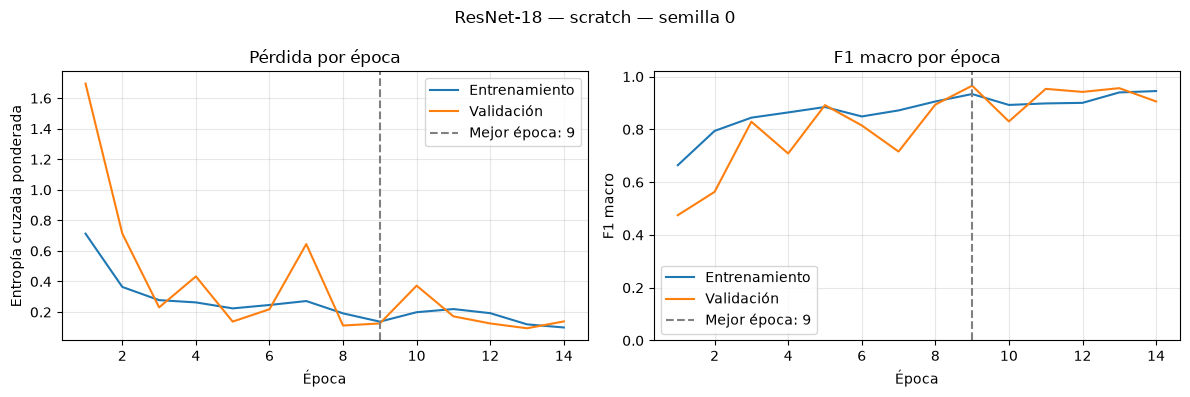

Curvas guardadas en: resultados\final\scratch_seed0\curvas.png


In [33]:
# Leemos las métricas guardadas durante el entrenamiento.
carpeta_ejecucion = Path("resultados/final/scratch_seed0")

with (carpeta_ejecucion / "history.csv").open(
    newline="", encoding="utf-8"
) as archivo:
    historial_scratch = list(csv.DictReader(archivo))

epocas = [int(fila["epoch"]) for fila in historial_scratch]

# Recuperamos la primera época que alcanzó el mejor F1 de validación.
mejor_fila = max(
    historial_scratch,
    key=lambda fila: float(fila["val_f1_macro"]),
)
mejor_epoca = int(mejor_fila["epoch"])

figura, ejes = plt.subplots(1, 2, figsize=(12, 4))

for particion, etiqueta in [
    ("train", "Entrenamiento"),
    ("val", "Validación"),
]:
    ejes[0].plot(
        epocas,
        [float(fila[f"{particion}_loss"]) for fila in historial_scratch],
        label=etiqueta,
    )

    ejes[1].plot(
        epocas,
        [float(fila[f"{particion}_f1_macro"]) for fila in historial_scratch],
        label=etiqueta,
    )

ejes[0].set_title("Pérdida por época")
ejes[0].set_ylabel("Entropía cruzada ponderada")

ejes[1].set_title("F1 macro por época")
ejes[1].set_ylabel("F1 macro")
ejes[1].set_ylim(0, 1.02)

for eje in ejes:
    eje.axvline(
        mejor_epoca,
        color="gray",
        linestyle="--",
        label=f"Mejor época: {mejor_epoca}",
    )
    eje.set_xlabel("Época")
    eje.grid(alpha=0.3)
    eje.legend()

figura.suptitle("ResNet-18 — scratch — semilla 0")
figura.tight_layout()

ruta_figura = carpeta_ejecucion / "curvas.png"
figura.savefig(ruta_figura, dpi=200, bbox_inches="tight")

plt.show()

print("Curvas guardadas en:", ruta_figura)

### 5.9. Ejecución de las tres estrategias y semillas

Comparamos entrenamiento desde cero, extracción de características y
ajuste fino, utilizando las semillas 0, 1 y 2.

Todas las ejecuciones comparten las mismas particiones, tamaño de lote,
máximo de épocas y criterio de parada temprana.

Las ejecuciones terminadas se recuperan desde sus checkpoints.
Guardamos un resumen después de cada combinación completada.
La partición de prueba permanece reservada.

In [34]:
resumenes_entrenamiento = []

ruta_resumen = Path("resultados/final/summary.csv")
ruta_resumen.parent.mkdir(parents=True, exist_ok=True)

for estrategia in config_entrenamiento["strategies"]:
    for semilla in config_entrenamiento["seeds"]:
        print(
            f"\nCombinación: {estrategia} | semilla: {semilla}",
            flush=True,
        )

        # La función recupera las ejecuciones ya terminadas
        # y reanuda las que quedaron incompletas.
        resumen = entrenar_modelo(
            estrategia=estrategia,
            semilla=semilla,
        )

        resumenes_entrenamiento.append(resumen)

        # Actualizamos el resumen después de cada ejecución terminada.
        guardar_historial(
            resumenes_entrenamiento,
            ruta_resumen,
        )

print("\nRESUMEN DE ENTRENAMIENTOS")
print("Estrategia          Semilla  Épocas  Mejor época  F1 validación")

for resumen in resumenes_entrenamiento:
    print(
        f"{resumen['strategy']:<20}"
        f"{resumen['seed']:<9}"
        f"{resumen['epochs_completed']:<8}"
        f"{resumen['best_epoch']:<13}"
        f"{resumen['best_val_f1']:.4f}"
    )

print(
    f"\nEjecuciones completadas: "
    f"{len(resumenes_entrenamiento)}/9"
)
print("Resumen guardado en:", ruta_resumen)


Combinación: scratch | semilla: 0
Estado recuperado: scratch_seed0, época 14.

Entrenamiento: scratch_seed0
Parada temprana: se agotó la paciencia.
Finalizado: scratch_seed0 | Mejor época: 9 | Mejor F1 de validación: 0.9655

Combinación: scratch | semilla: 1

Entrenamiento: scratch_seed1
Época 01/20 | train_loss: 0.7590 | train_F1: 0.6642 | val_loss: 0.5013 | val_F1: 0.6620 | 12.1 s
  → Nuevo mejor modelo guardado.
Época 02/20 | train_loss: 0.3911 | train_F1: 0.7842 | val_loss: 0.5382 | val_F1: 0.6240 | 10.6 s
  → Sin mejora: 1/5.
Época 03/20 | train_loss: 0.3490 | train_F1: 0.8222 | val_loss: 0.4639 | val_F1: 0.6154 | 10.6 s
  → Sin mejora: 2/5.
Época 04/20 | train_loss: 0.2499 | train_F1: 0.8689 | val_loss: 0.3360 | val_F1: 0.8926 | 10.1 s
  → Nuevo mejor modelo guardado.
Época 05/20 | train_loss: 0.2545 | train_F1: 0.8765 | val_loss: 0.2813 | val_F1: 0.8280 | 9.9 s
  → Sin mejora: 1/5.
Época 06/20 | train_loss: 0.2666 | train_F1: 0.8657 | val_loss: 0.3511 | val_F1: 0.7038 | 9.9 s
 

100.0%



Entrenamiento: feature_extraction_seed0
Época 01/20 | train_loss: 0.6403 | train_F1: 0.7311 | val_loss: 0.2896 | val_F1: 0.9085 | 9.5 s
  → Nuevo mejor modelo guardado.
Época 02/20 | train_loss: 0.2409 | train_F1: 0.9005 | val_loss: 0.1954 | val_F1: 0.9337 | 9.1 s
  → Nuevo mejor modelo guardado.
Época 03/20 | train_loss: 0.1738 | train_F1: 0.9307 | val_loss: 0.1541 | val_F1: 0.9370 | 9.2 s
  → Nuevo mejor modelo guardado.
Época 04/20 | train_loss: 0.1323 | train_F1: 0.9362 | val_loss: 0.1495 | val_F1: 0.9466 | 9.2 s
  → Nuevo mejor modelo guardado.
Época 05/20 | train_loss: 0.1205 | train_F1: 0.9447 | val_loss: 0.1406 | val_F1: 0.9433 | 9.3 s
  → Sin mejora: 1/5.
Época 06/20 | train_loss: 0.1081 | train_F1: 0.9459 | val_loss: 0.1196 | val_F1: 0.9401 | 9.2 s
  → Sin mejora: 2/5.
Época 07/20 | train_loss: 0.0835 | train_F1: 0.9637 | val_loss: 0.1154 | val_F1: 0.9468 | 9.4 s
  → Nuevo mejor modelo guardado.
Época 08/20 | train_loss: 0.0861 | train_F1: 0.9590 | val_loss: 0.1071 | val_F1:

### 5.10. Comparación y selección mediante validación

Comparamos las estrategias mediante la media y la desviación estándar
muestral de sus tres semillas.

Para cada ejecución, tomamos las métricas de la época seleccionada
por el mayor F1 macro de validación.

Elegimos la estrategia con mayor F1 macro medio de validación.
Para la demostración utilizaremos su ejecución con semilla 0.
Esta selección se registra antes de evaluar en prueba.

In [45]:
from statistics import mean, stdev

carpeta_final = Path("resultados/final")
ruta_resumen = carpeta_final / "summary.csv"

with ruta_resumen.open(newline="", encoding="utf-8") as archivo:
    ejecuciones = list(csv.DictReader(archivo))

# Comprobamos que estén las nueve combinaciones esperadas.
esperadas = {
    (estrategia, semilla)
    for estrategia in config_entrenamiento["strategies"]
    for semilla in config_entrenamiento["seeds"]
}

encontradas = {
    (fila["strategy"], int(fila["seed"]))
    for fila in ejecuciones
}

assert len(ejecuciones) == len(esperadas)
assert encontradas == esperadas

resultados_validacion = []

for ejecucion in ejecuciones:
    estrategia = ejecucion["strategy"]
    semilla = int(ejecucion["seed"])
    mejor_epoca = int(ejecucion["best_epoch"])

    ruta_historial = (
        carpeta_final
        / f"{estrategia}_seed{semilla}"
        / "history.csv"
    )

    with ruta_historial.open(
        newline="", encoding="utf-8"
    ) as archivo:
        historial = list(csv.DictReader(archivo))

    # Tomamos exactitud y F1 de la misma época seleccionada.
    mejor_fila = next(
        fila for fila in historial
        if int(fila["epoch"]) == mejor_epoca
    )

    resultados_validacion.append({
        "strategy": estrategia,
        "seed": semilla,
        "best_epoch": mejor_epoca,
        "val_accuracy": float(mejor_fila["val_accuracy"]),
        "val_f1_macro": float(mejor_fila["val_f1_macro"]),
        "duration_seconds": float(ejecucion["duration_seconds"]),
    })

comparacion_validacion = []

for estrategia in config_entrenamiento["strategies"]:
    filas = [
        fila for fila in resultados_validacion
        if fila["strategy"] == estrategia
    ]

    exactitudes = [fila["val_accuracy"] for fila in filas]
    valores_f1 = [fila["val_f1_macro"] for fila in filas]

    comparacion_validacion.append({
        "strategy": estrategia,
        "runs": len(filas),
        "val_accuracy_mean": mean(exactitudes),
        "val_accuracy_std": stdev(exactitudes),
        "val_f1_macro_mean": mean(valores_f1),
        "val_f1_macro_std": stdev(valores_f1),
    })

# Guardamos las tablas por ejecución y por estrategia.
guardar_historial(
    resultados_validacion,
    carpeta_final / "validation_runs.csv",
)

guardar_historial(
    comparacion_validacion,
    carpeta_final / "validation_summary.csv",
)

# Seleccionamos la estrategia mediante validación.
ganadora = max(
    comparacion_validacion,
    key=lambda fila: fila["val_f1_macro_mean"],
)

estrategia_seleccionada = ganadora["strategy"]

# Para la demostración elegimos la semilla 2.
# Esta decisión se tomó después de observar los resultados de prueba.
semilla_demo = 2

ejecucion_demo = next(
    fila for fila in ejecuciones
    if fila["strategy"] == estrategia_seleccionada
    and int(fila["seed"]) == semilla_demo
)

seleccion = {
    "strategy": estrategia_seleccionada,
    "seed": semilla_demo,
    "criterion": "strategy_by_validation_and_demo_seed_after_test",
    "selected_after_test": True,
    "mean_val_f1_macro": ganadora["val_f1_macro_mean"],
    "checkpoint": Path(
        ejecucion_demo["best_checkpoint"]
    ).as_posix(),
    "training_summary_sha256": hashlib.sha256(
        ruta_resumen.read_bytes()
    ).hexdigest(),
}

# Reemplazamos el archivo con la selección actual.
ruta_seleccion = carpeta_final / "selection.json"

ruta_seleccion.write_text(
    json.dumps(seleccion, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("COMPARACIÓN EN VALIDACIÓN")
print("Exactitud en porcentaje; F1 macro entre 0 y 1.\n")

for fila in comparacion_validacion:
    print(
        f"{fila['strategy']}: "
        f"exactitud = {100 * fila['val_accuracy_mean']:.2f}% "
        f"± {100 * fila['val_accuracy_std']:.2f} puntos; "
        f"F1 macro = {fila['val_f1_macro_mean']:.4f} "
        f"± {fila['val_f1_macro_std']:.4f}"
    )

print("\nEstrategia seleccionada:", estrategia_seleccionada)
print("Semilla para la demostración:", seleccion["seed"])
print("Tablas y selección guardadas.")

COMPARACIÓN EN VALIDACIÓN
Exactitud en porcentaje; F1 macro entre 0 y 1.

scratch: exactitud = 93.90% ± 2.76 puntos; F1 macro = 0.9381 ± 0.0397
feature_extraction: exactitud = 96.91% ± 0.35 puntos; F1 macro = 0.9387 ± 0.0104
finetune: exactitud = 99.54% ± 0.40 puntos; F1 macro = 0.9924 ± 0.0069

Estrategia seleccionada: finetune
Semilla para la demostración: 2
Tablas y selección guardadas.


### 5.11. Curvas de aprendizaje de las nueve ejecuciones

Mostramos la evolución de la pérdida, la exactitud y el F1 macro de
entrenamiento y validación para cada estrategia y semilla.

La línea vertical señala la época seleccionada por el mayor F1 macro
de validación. Estas figuras se generan a partir de los historiales
guardados; no requieren volver a entrenar.

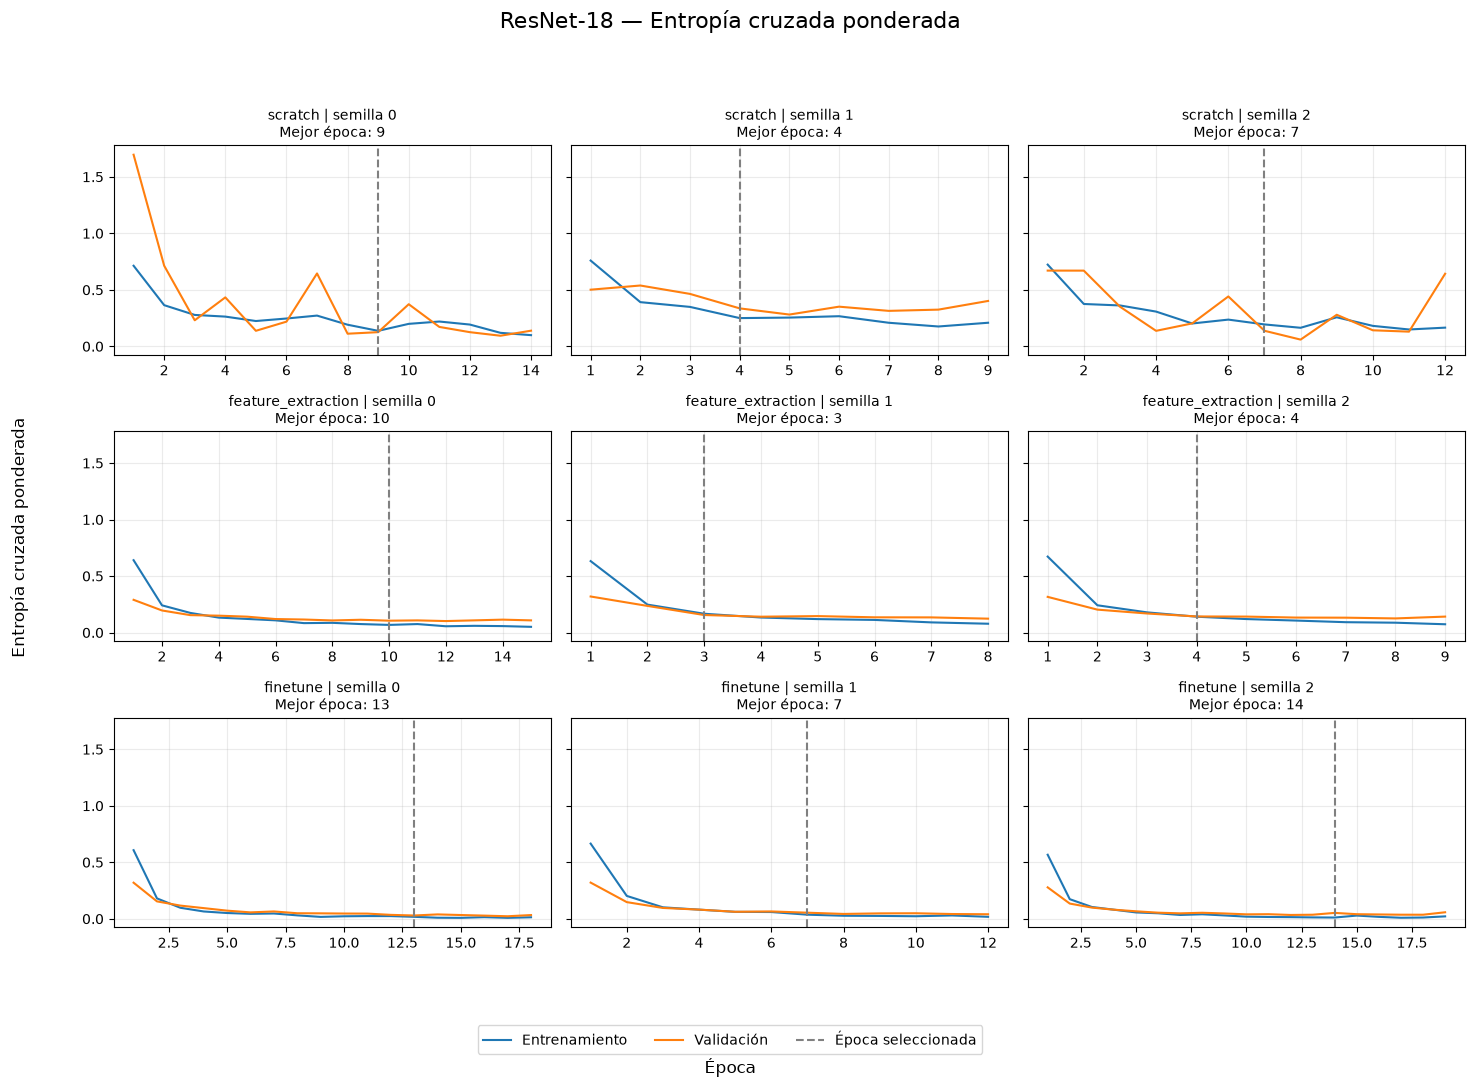

Figura guardada en: resultados\final\curvas_loss.png


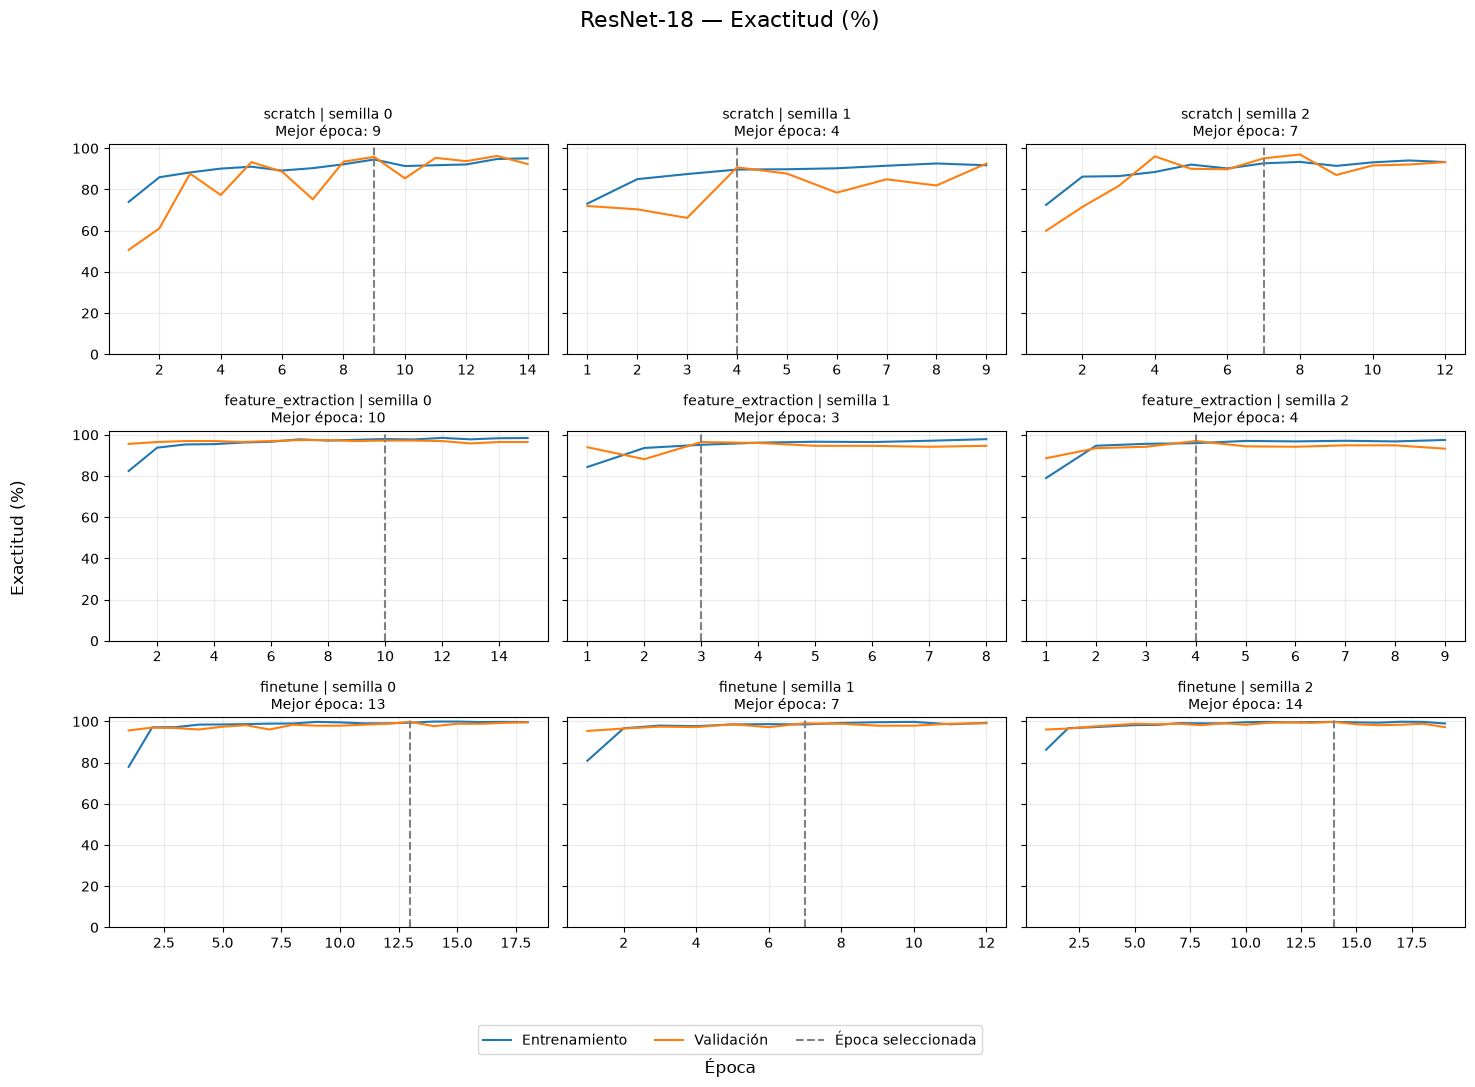

Figura guardada en: resultados\final\curvas_accuracy.png


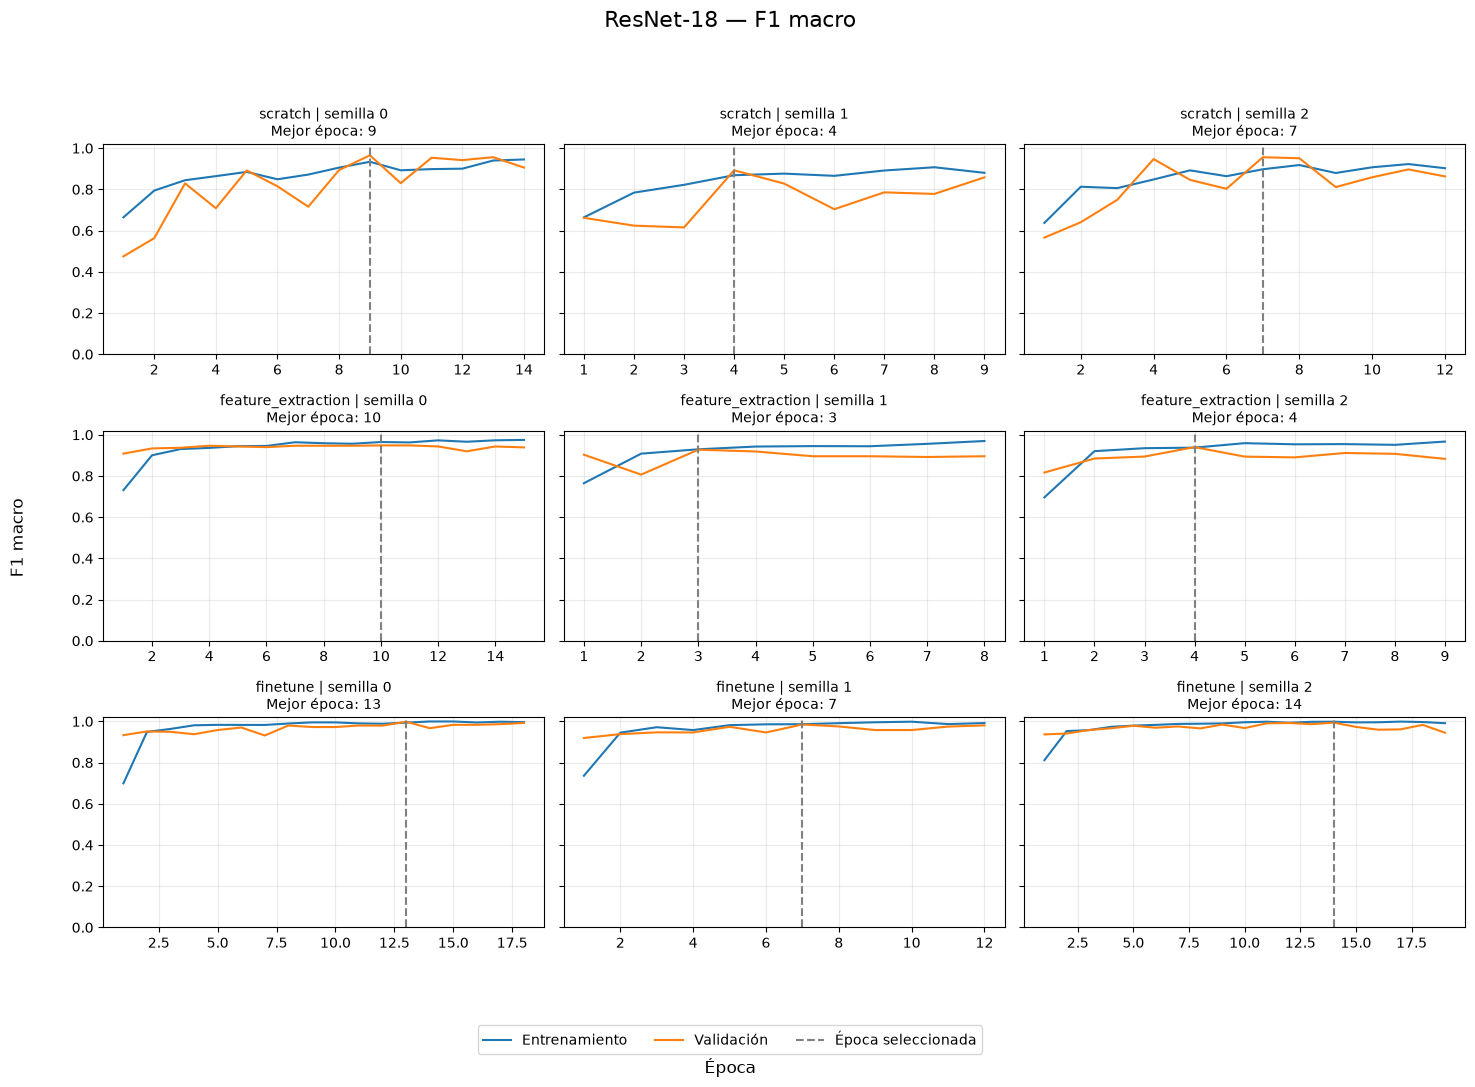

Figura guardada en: resultados\final\curvas_f1_macro.png


In [36]:
# Leemos el resumen y los historiales de las nueve ejecuciones.
carpeta_final = Path("resultados/final")

with (carpeta_final / "summary.csv").open(
    newline="", encoding="utf-8"
) as archivo:
    ejecuciones = list(csv.DictReader(archivo))

historiales = {}
mejores_epocas = {}

for ejecucion in ejecuciones:
    estrategia = ejecucion["strategy"]
    semilla = int(ejecucion["seed"])
    clave = (estrategia, semilla)

    ruta_historial = (
        carpeta_final
        / f"{estrategia}_seed{semilla}"
        / "history.csv"
    )

    with ruta_historial.open(
        newline="", encoding="utf-8"
    ) as archivo:
        historiales[clave] = list(csv.DictReader(archivo))

    mejores_epocas[clave] = int(ejecucion["best_epoch"])

# La exactitud se representa como porcentaje.
metricas_curvas = [
    ("loss", "Entropía cruzada ponderada", 1),
    ("accuracy", "Exactitud (%)", 100),
    ("f1_macro", "F1 macro", 1),
]

estrategias = config_entrenamiento["strategies"]
semillas = config_entrenamiento["seeds"]

for metrica, nombre_metrica, factor in metricas_curvas:
    figura, ejes = plt.subplots(
        len(estrategias),
        len(semillas),
        figsize=(15, 11),
        sharey=True,
    )

    for fila, estrategia in enumerate(estrategias):
        for columna, semilla in enumerate(semillas):
            eje = ejes[fila, columna]
            clave = (estrategia, semilla)
            historial = historiales[clave]

            epocas = [
                int(registro["epoch"])
                for registro in historial
            ]

            for particion, etiqueta in [
                ("train", "Entrenamiento"),
                ("val", "Validación"),
            ]:
                valores = [
                    float(registro[f"{particion}_{metrica}"]) * factor
                    for registro in historial
                ]

                eje.plot(epocas, valores, label=etiqueta)

            mejor_epoca = mejores_epocas[clave]

            eje.axvline(
                mejor_epoca,
                color="gray",
                linestyle="--",
                label="Época seleccionada",
            )

            eje.set_title(
                f"{estrategia} | semilla {semilla}\n"
                f"Mejor época: {mejor_epoca}",
                fontsize=10,
            )

            eje.grid(alpha=0.25)

            if metrica != "loss":
                eje.set_ylim(0, factor * 1.02)

    figura.suptitle(
        f"ResNet-18 — {nombre_metrica}",
        fontsize=16,
    )
    figura.supxlabel("Época")
    figura.supylabel(nombre_metrica)

    # Una leyenda compartida evita repetirla en los nueve paneles.
    elementos, etiquetas = ejes[0, 0].get_legend_handles_labels()

    figura.legend(
        elementos,
        etiquetas,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, 0.025),
    )

    figura.tight_layout(rect=(0.03, 0.08, 1, 0.94))

    ruta_figura = carpeta_final / f"curvas_{metrica}.png"

    figura.savefig(
        ruta_figura,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figura)

    print("Figura guardada en:", ruta_figura)

### 5.12. Evaluación del modelo seleccionado en prueba

Cargamos los mejores pesos del modelo seleccionado mediante validación.

Calculamos exactitud, precisión, recall y F1 por clase, además del
F1 macro y la matriz de confusión. Guardamos también las predicciones
individuales para analizar los aciertos y errores.

Los resultados de prueba se utilizan para la evaluación final,
sin modificar el entrenamiento ni la selección.

In [37]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


@torch.inference_mode()
def evaluar_prueba(estrategia, semilla, mostrar=False):
    nombre = f"{estrategia}_seed{semilla}"
    carpeta = Path("resultados/final") / nombre
    ruta_pesos = Path("checkpoints/final") / nombre / "best.pt"

    checkpoint = torch.load(
        ruta_pesos,
        map_location="cpu",
        weights_only=True,
    )

    configuracion = checkpoint["config"]

    # Comprobamos que las clases y las particiones sean las originales.
    huella_particiones = hashlib.sha256(
        Path("resultados/particiones.csv").read_bytes()
    ).hexdigest()

    assert configuracion["strategy"] == estrategia
    assert configuracion["seed"] == semilla
    assert configuracion["classes"] == clase_a_indice
    assert configuracion["split_sha256"] == huella_particiones
    assert configuracion["eval_transform"] == str(transformacion_eval)

    # Recuperamos el modelo entrenado y activamos evaluación.
    modelo = crear_modelo(estrategia)
    modelo.load_state_dict(checkpoint["model_state_dict"])
    modelo = modelo.to(dispositivo)
    modelo.eval()

    # Conservamos el orden para asociar cada predicción con su imagen.
    loader_prueba = DataLoader(
        dataset_test,
        batch_size=configuracion["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=dispositivo.type == "cuda",
    )

    reales = []
    predichas = []
    probabilidades = []

    usar_amp = (
        configuracion["amp"]
        and dispositivo.type == "cuda"
    )

    for imagenes, etiquetas in loader_prueba:
        imagenes = imagenes.to(dispositivo, non_blocking=True)

        # Mantenemos el criterio de precisión utilizado en validación.
        with torch.autocast(
            device_type=dispositivo.type,
            dtype=torch.float16,
            enabled=usar_amp,
        ):
            salidas = modelo(imagenes)

        probabilidades_lote = salidas.float().softmax(dim=1)
        predicciones = salidas.argmax(dim=1)

        reales.extend(etiquetas.tolist())
        predichas.extend(predicciones.cpu().tolist())
        probabilidades.extend(probabilidades_lote.cpu().tolist())

    # Verificamos la correspondencia con los registros del dataset.
    assert len(reales) == len(dataset_test)
    assert reales == [
        clase_a_indice[registro["clase"]]
        for registro in dataset_test.registros
    ]

    clases_ordenadas = sorted(
        clase_a_indice,
        key=clase_a_indice.get,
    )
    nombres = [clases[clase] for clase in clases_ordenadas]
    indices = list(range(len(nombres)))

    reporte = classification_report(
        reales,
        predichas,
        labels=indices,
        target_names=nombres,
        output_dict=True,
        zero_division=0,
    )

    matriz = confusion_matrix(
        reales,
        predichas,
        labels=indices,
    )

    metricas = {
        "strategy": estrategia,
        "seed": semilla,
        "best_epoch": checkpoint["epoch"],
        "test_images": len(reales),
        "test_accuracy": float(accuracy_score(reales, predichas)),
        "test_precision_macro": reporte["macro avg"]["precision"],
        "test_recall_macro": reporte["macro avg"]["recall"],
        "test_f1_macro": reporte["macro avg"]["f1-score"],
    }

    # Guardamos las métricas y la matriz como datos.
    contenido = {
        "metrics": metricas,
        "classification_report": reporte,
        "confusion_matrix": matriz.tolist(),
        "classes": nombres,
        "split_sha256": huella_particiones,
        "checkpoint_sha256": hashlib.sha256(
            ruta_pesos.read_bytes()
        ).hexdigest(),
        "inference_amp": usar_amp,
    }

    (carpeta / "test_metrics.json").write_text(
        json.dumps(contenido, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    # Exportamos la tabla de métricas por clase.
    tabla_clases = [
        {
            "class": nombre_clase,
            "precision": reporte[nombre_clase]["precision"],
            "recall": reporte[nombre_clase]["recall"],
            "f1": reporte[nombre_clase]["f1-score"],
            "support": int(reporte[nombre_clase]["support"]),
        }
        for nombre_clase in nombres
    ]

    guardar_historial(
        tabla_clases,
        carpeta / "test_per_class.csv",
    )

    # Guardamos cada predicción para analizar errores y hacer la demo.
    tabla_predicciones = []

    for registro, real, predicha, probabilidades_imagen in zip(
        dataset_test.registros,
        reales,
        predichas,
        probabilidades,
    ):
        tabla_predicciones.append({
            "path": registro["ruta"],
            "leaf": registro["hoja"],
            "true_label": real,
            "predicted_label": predicha,
            "correct": int(real == predicha),
            "confidence": probabilidades_imagen[predicha],
            **{
                f"prob_{indice}": probabilidad
                for indice, probabilidad
                in enumerate(probabilidades_imagen)
            },
        })

    guardar_historial(
        tabla_predicciones,
        carpeta / "test_predictions.csv",
    )

    # Generamos la matriz de confusión como figura.
    figura, eje = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=nombres,
    ).plot(
        ax=eje,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )

    eje.set_title(f"Prueba — {estrategia} — semilla {semilla}")
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
    figura.tight_layout()

    figura.savefig(
        carpeta / "test_confusion_matrix.png",
        dpi=200,
        bbox_inches="tight",
    )

    if mostrar:
        print(classification_report(
            reales,
            predichas,
            labels=indices,
            target_names=nombres,
            digits=4,
            zero_division=0,
        ))
        plt.show()

    plt.close(figura)

    return metricas


print("Función de evaluación en prueba preparada.")

Función de evaluación en prueba preparada.


                precision    recall  f1-score   support

Tizón temprano     0.9804    1.0000    0.9901       200
  Tizón tardío     1.0000    0.9450    0.9717       200
          Sana     0.8205    1.0000    0.9014        32

      accuracy                         0.9745       432
     macro avg     0.9336    0.9817    0.9544       432
  weighted avg     0.9776    0.9745    0.9750       432



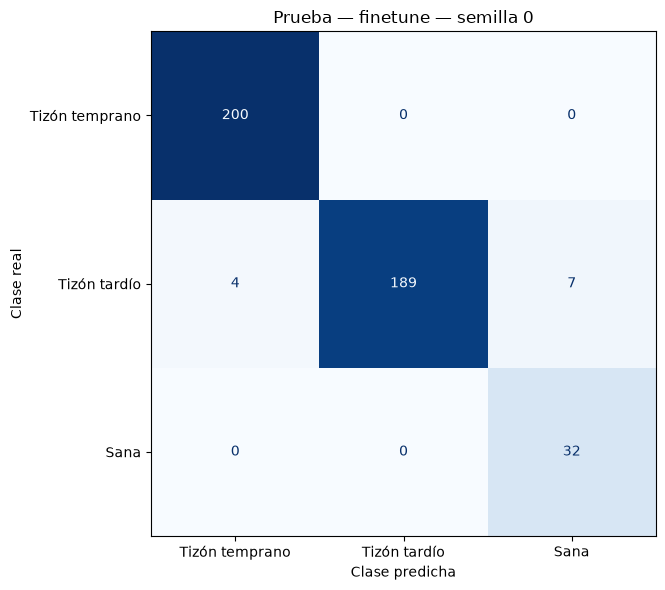

Exactitud en prueba: 97.45%
F1 macro en prueba: 0.9544
Resultados guardados.


In [38]:
# Leemos la selección que registramos antes de consultar prueba.
seleccion = json.loads(
    Path("resultados/final/selection.json").read_text(
        encoding="utf-8"
    )
)

# Comprobamos que el resumen de entrenamientos no haya cambiado.
assert seleccion["training_summary_sha256"] == hashlib.sha256(
    Path("resultados/final/summary.csv").read_bytes()
).hexdigest()

resumen_prueba_demo = evaluar_prueba(
    estrategia=seleccion["strategy"],
    semilla=seleccion["seed"],
    mostrar=True,
)

print(
    f"Exactitud en prueba: "
    f"{100 * resumen_prueba_demo['test_accuracy']:.2f}%"
)
print(
    f"F1 macro en prueba: "
    f"{resumen_prueba_demo['test_f1_macro']:.4f}"
)
print("Resultados guardados.")

### 5.13. Evaluación y comparación final de las nueve ejecuciones

Evaluamos en prueba los mejores modelos seleccionados mediante validación.

Recuperamos las evaluaciones ya guardadas y calculamos las pendientes.
Presentamos las métricas por ejecución y la media y desviación estándar
muestral de las tres semillas por estrategia.

La estrategia elegida para la demostración permanece sin cambios.

In [39]:
carpeta_final = Path("resultados/final")
ruta_resumen = carpeta_final / "summary.csv"

seleccion = json.loads(
    (carpeta_final / "selection.json").read_text(encoding="utf-8")
)

# Verificamos que seguimos evaluando los experimentos originales.
assert seleccion["training_summary_sha256"] == hashlib.sha256(
    ruta_resumen.read_bytes()
).hexdigest()

with ruta_resumen.open(newline="", encoding="utf-8") as archivo:
    ejecuciones = list(csv.DictReader(archivo))

huella_particiones = hashlib.sha256(
    Path("resultados/particiones.csv").read_bytes()
).hexdigest()

resultados_prueba = []

for ejecucion in ejecuciones:
    estrategia = ejecucion["strategy"]
    semilla = int(ejecucion["seed"])
    nombre = f"{estrategia}_seed{semilla}"

    ruta_metricas = carpeta_final / nombre / "test_metrics.json"

    if ruta_metricas.exists():
        # Recuperamos la evaluación ya realizada.
        guardado = json.loads(
            ruta_metricas.read_text(encoding="utf-8")
        )

        ruta_pesos = Path("checkpoints/final") / nombre / "best.pt"

        assert guardado["split_sha256"] == huella_particiones
        assert guardado["checkpoint_sha256"] == hashlib.sha256(
            ruta_pesos.read_bytes()
        ).hexdigest()

        metricas = guardado["metrics"]
    else:
        # Esta función evalúa; no actualiza los pesos.
        metricas = evaluar_prueba(
            estrategia=estrategia,
            semilla=semilla,
        )

    assert metricas["strategy"] == estrategia
    assert metricas["seed"] == semilla
    assert metricas["best_epoch"] == int(ejecucion["best_epoch"])
    assert metricas["test_images"] == len(dataset_test)

    resultados_prueba.append({
        **metricas,
        "best_val_f1": float(ejecucion["best_val_f1"]),
        "epochs_completed": int(ejecucion["epochs_completed"]),
        "training_validation_seconds": float(
            ejecucion["duration_seconds"]
        ),
    })

    # Conservamos el avance después de cada modelo evaluado.
    guardar_historial(
        resultados_prueba,
        carpeta_final / "test_runs.csv",
    )

    print(
        f"{nombre}: "
        f"exactitud = {100 * metricas['test_accuracy']:.2f}% | "
        f"F1 macro = {metricas['test_f1_macro']:.4f}",
        flush=True,
    )

# Resumimos las tres semillas de cada estrategia.
comparacion_prueba = []

for estrategia in config_entrenamiento["strategies"]:
    filas = [
        fila for fila in resultados_prueba
        if fila["strategy"] == estrategia
    ]

    assert len(filas) == 3

    resumen = {
        "strategy": estrategia,
        "runs": len(filas),
    }

    for metrica in [
        "test_accuracy",
        "test_precision_macro",
        "test_recall_macro",
        "test_f1_macro",
    ]:
        valores = [fila[metrica] for fila in filas]
        resumen[f"{metrica}_mean"] = mean(valores)
        resumen[f"{metrica}_std"] = stdev(valores)

    comparacion_prueba.append(resumen)

guardar_historial(
    comparacion_prueba,
    carpeta_final / "test_summary.csv",
)

print("\nCOMPARACIÓN FINAL EN PRUEBA")

for fila in comparacion_prueba:
    print(
        f"{fila['strategy']}: "
        f"exactitud = {100 * fila['test_accuracy_mean']:.2f}% "
        f"± {100 * fila['test_accuracy_std']:.2f} puntos | "
        f"F1 macro = {fila['test_f1_macro_mean']:.4f} "
        f"± {fila['test_f1_macro_std']:.4f}"
    )

print("\nEvaluaciones completadas:", len(resultados_prueba), "/9")
print("Tablas finales guardadas.")

scratch_seed0: exactitud = 90.74% | F1 macro = 0.9039
scratch_seed1: exactitud = 87.04% | F1 macro = 0.8449
scratch_seed2: exactitud = 91.44% | F1 macro = 0.9028
feature_extraction_seed0: exactitud = 95.37% | F1 macro = 0.9252
feature_extraction_seed1: exactitud = 93.75% | F1 macro = 0.8982
feature_extraction_seed2: exactitud = 92.36% | F1 macro = 0.8813
finetune_seed0: exactitud = 97.45% | F1 macro = 0.9544
finetune_seed1: exactitud = 97.92% | F1 macro = 0.9578
finetune_seed2: exactitud = 99.07% | F1 macro = 0.9770

COMPARACIÓN FINAL EN PRUEBA
scratch: exactitud = 89.74% ± 2.36 puntos | F1 macro = 0.8839 ± 0.0338
feature_extraction: exactitud = 93.83% ± 1.51 puntos | F1 macro = 0.9016 ± 0.0221
finetune: exactitud = 98.15% ± 0.83 puntos | F1 macro = 0.9631 ± 0.0122

Evaluaciones completadas: 9 /9
Tablas finales guardadas.


### 5.14. Visualización de los resultados finales

Comparamos la exactitud y el F1 macro de prueba mediante la media
y la desviación estándar de las tres semillas por estrategia.

También presentamos las matrices de confusión para identificar
las categorías que confunde cada modelo.

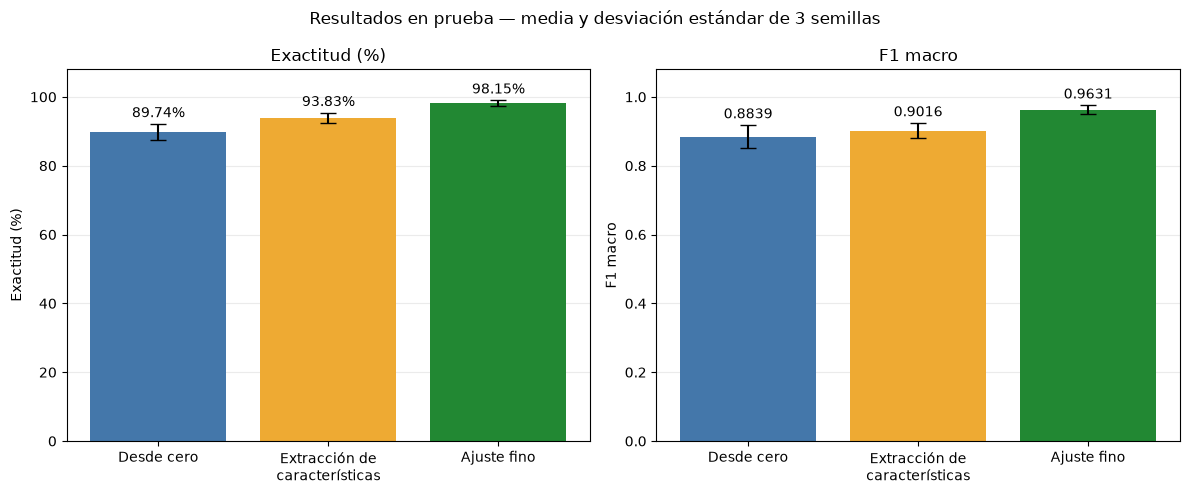

Figura guardada en: resultados\final\comparacion_prueba.png


In [40]:
# Recuperamos los promedios y desviaciones ya calculados.
carpeta_final = Path("resultados/final")

with (carpeta_final / "test_summary.csv").open(
    newline="", encoding="utf-8"
) as archivo:
    comparacion = list(csv.DictReader(archivo))

etiquetas = {
    "scratch": "Desde cero",
    "feature_extraction": "Extracción de\ncaracterísticas",
    "finetune": "Ajuste fino",
}

posiciones = np.arange(len(comparacion))
nombres = [etiquetas[fila["strategy"]] for fila in comparacion]
colores = ["#4477AA", "#EEAA33", "#228833"]

figura, ejes = plt.subplots(1, 2, figsize=(12, 5))

for eje, metrica, titulo, factor in [
    (ejes[0], "test_accuracy", "Exactitud (%)", 100),
    (ejes[1], "test_f1_macro", "F1 macro", 1),
]:
    medias = [
        float(fila[f"{metrica}_mean"]) * factor
        for fila in comparacion
    ]
    desviaciones = [
        float(fila[f"{metrica}_std"]) * factor
        for fila in comparacion
    ]

    eje.bar(
        posiciones,
        medias,
        yerr=desviaciones,
        capsize=6,
        color=colores,
    )

    eje.set_xticks(posiciones)
    eje.set_xticklabels(nombres)
    eje.set_ylabel(titulo)
    eje.set_title(titulo)
    eje.set_ylim(0, factor * 1.08)
    eje.set_axisbelow(True)
    eje.grid(axis="y", alpha=0.25)

    for posicion, media, desviacion in zip(
        posiciones, medias, desviaciones
    ):
        texto = (
            f"{media:.2f}%"
            if metrica == "test_accuracy"
            else f"{media:.4f}"
        )
        eje.text(
            posicion,
            media + desviacion + factor * 0.02,
            texto,
            ha="center",
        )

figura.suptitle(
    "Resultados en prueba — media y desviación estándar de 3 semillas"
)
figura.tight_layout()

ruta_figura = carpeta_final / "comparacion_prueba.png"
figura.savefig(ruta_figura, dpi=200, bbox_inches="tight")

plt.show()
plt.close(figura)

print("Figura guardada en:", ruta_figura)

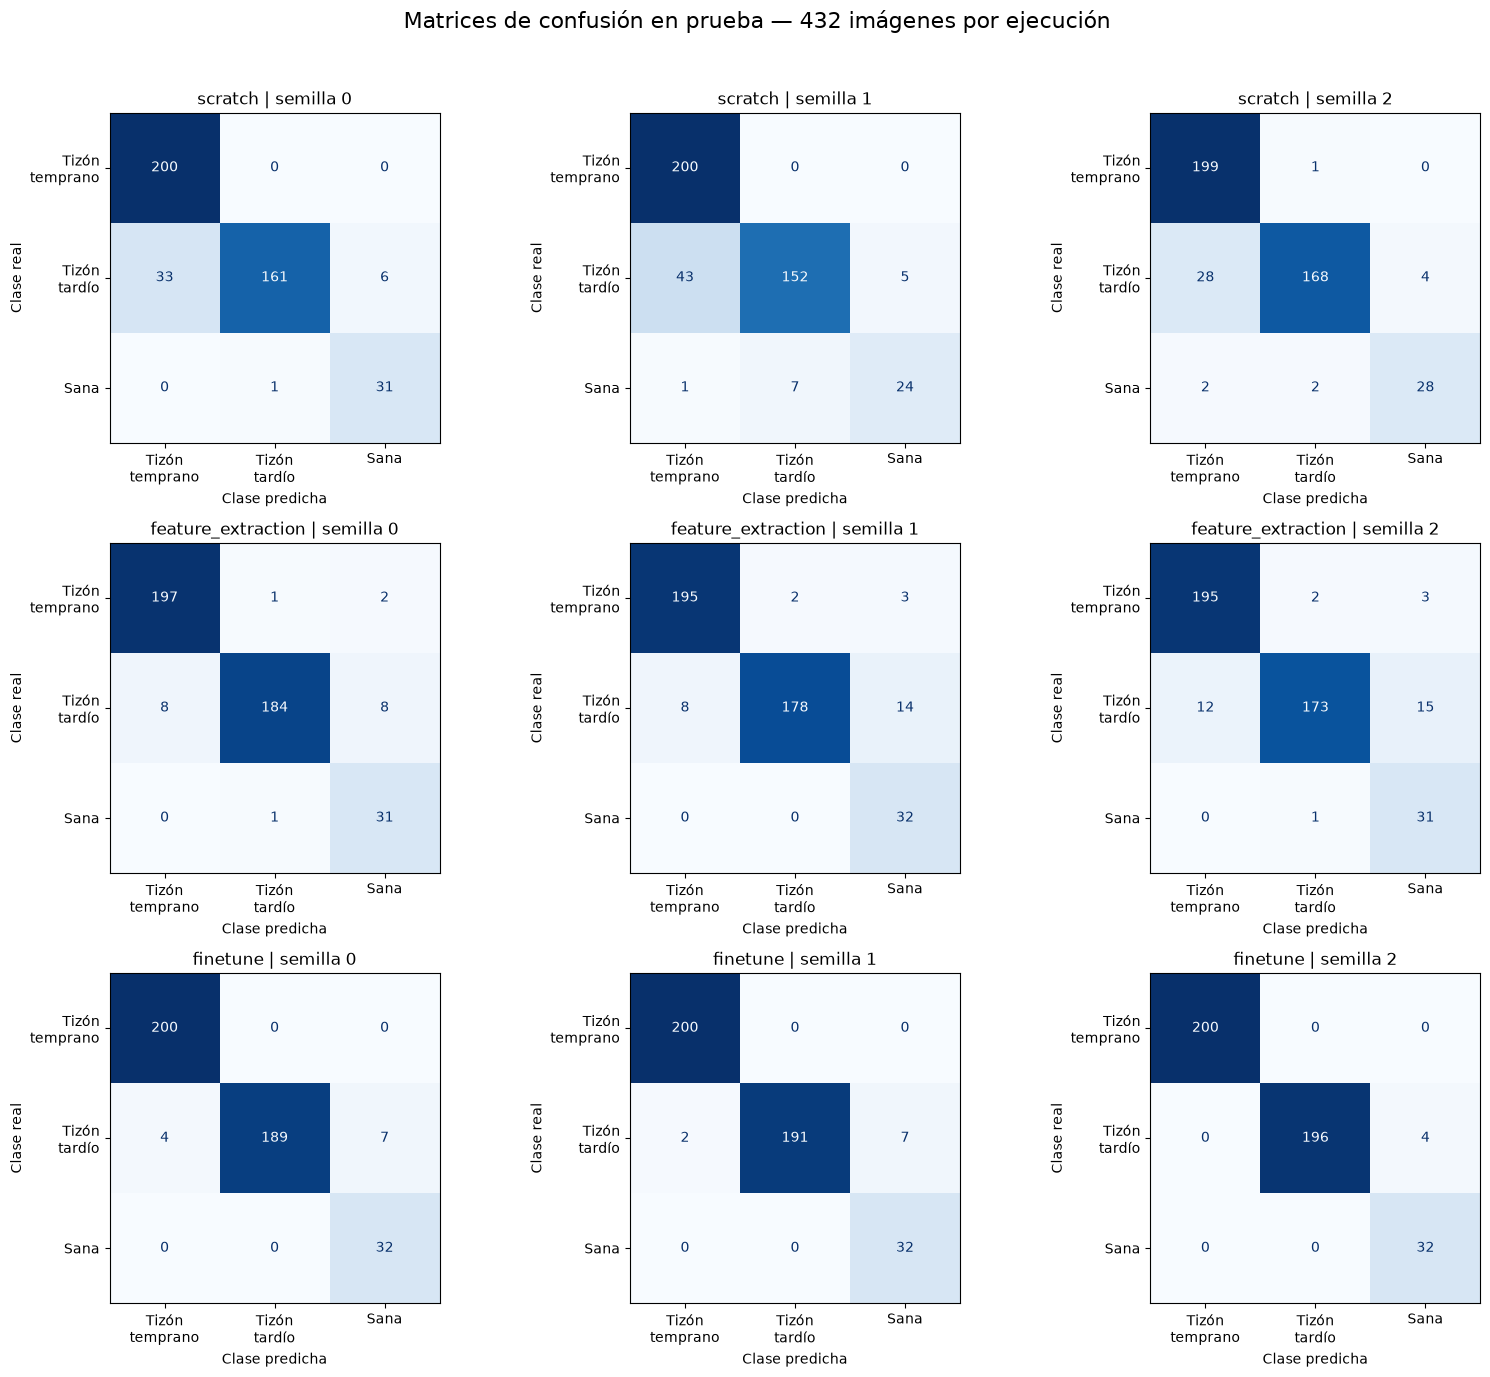

Matrices guardadas en: resultados\final\matrices_prueba.png


In [41]:
estrategias = config_entrenamiento["strategies"]
semillas = config_entrenamiento["seeds"]

reportes_prueba = {}

for estrategia in estrategias:
    for semilla in semillas:
        ruta = (
            carpeta_final
            / f"{estrategia}_seed{semilla}"
            / "test_metrics.json"
        )

        reportes_prueba[(estrategia, semilla)] = json.loads(
            ruta.read_text(encoding="utf-8")
        )

# Utilizamos la misma escala de color en los nueve paneles.
maximo = max(
    np.array(reporte["confusion_matrix"]).max()
    for reporte in reportes_prueba.values()
)

figura, ejes = plt.subplots(3, 3, figsize=(16, 14))

for fila, estrategia in enumerate(estrategias):
    for columna, semilla in enumerate(semillas):
        reporte = reportes_prueba[(estrategia, semilla)]
        eje = ejes[fila, columna]

        nombres_clases = [
            nombre.replace(" ", "\n", 1)
            for nombre in reporte["classes"]
        ]

        ConfusionMatrixDisplay(
            confusion_matrix=np.array(reporte["confusion_matrix"]),
            display_labels=nombres_clases,
        ).plot(
            ax=eje,
            cmap="Blues",
            colorbar=False,
            values_format="d",
            im_kw={"vmin": 0, "vmax": maximo},
        )

        eje.set_title(f"{estrategia} | semilla {semilla}")
        eje.set_xlabel("Clase predicha")
        eje.set_ylabel("Clase real")

figura.suptitle(
    "Matrices de confusión en prueba — 432 imágenes por ejecución",
    fontsize=16,
)
figura.tight_layout(rect=(0, 0, 1, 0.96))

ruta_matrices = carpeta_final / "matrices_prueba.png"
figura.savefig(ruta_matrices, dpi=200, bbox_inches="tight")

plt.show()
plt.close(figura)

print("Matrices guardadas en:", ruta_matrices)

### 5.15. Ejemplos de aciertos y errores

Seleccionamos un acierto de cada clase y ejemplos de las confusiones
del modelo elegido para la demostración.

Utilizamos hojas distintas y mostramos el mismo redimensionado y recorte
que se emplearon durante la evaluación. Estos ejemplos son ilustrativos;
las métricas anteriores consideran todas las imágenes de prueba.

Guardamos la selección para utilizar las mismas imágenes con Grad-CAM.

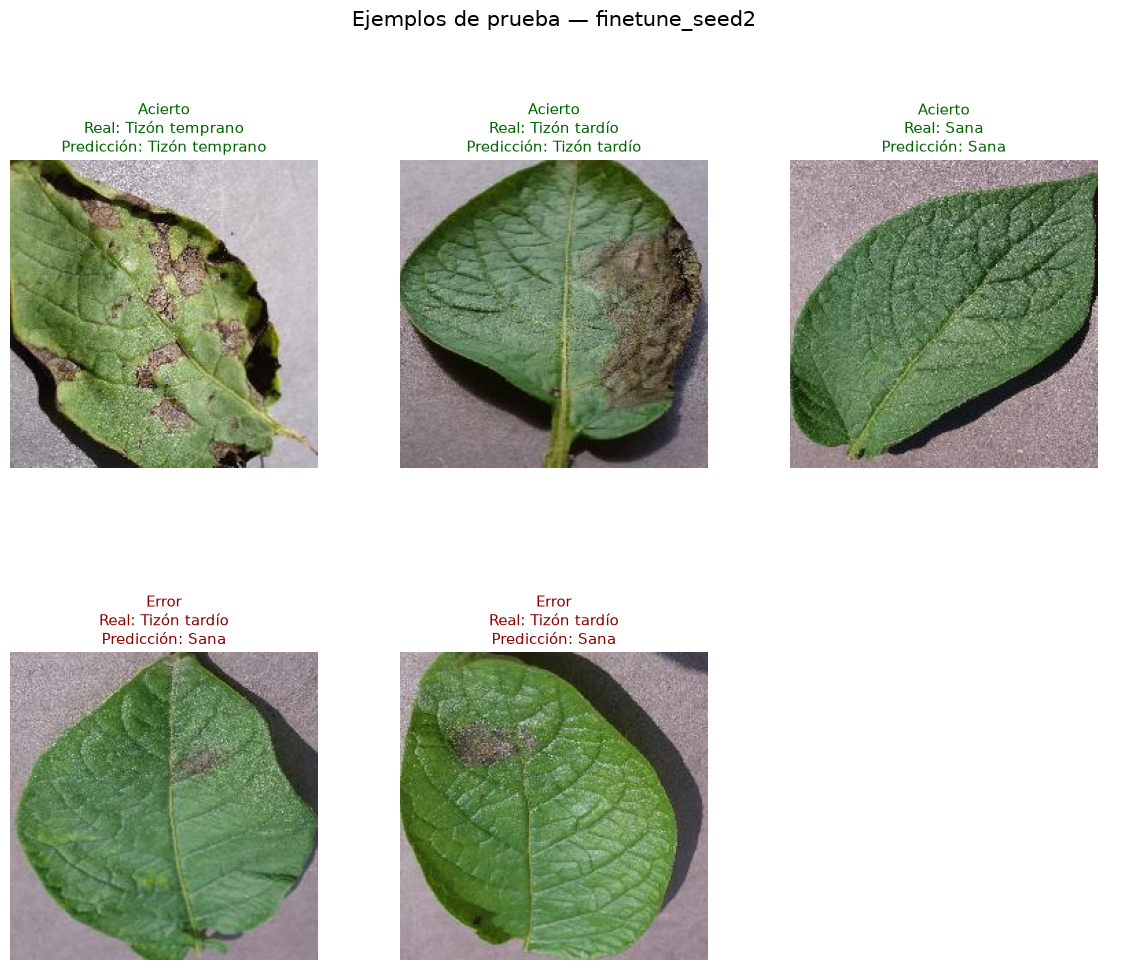

Ejemplos guardados en: resultados\final\finetune_seed2\aciertos_errores.png
Selección guardada en: resultados\final\finetune_seed2\demo_cases.csv


In [47]:
# Recuperamos la selección registrada antes de evaluar en prueba.
seleccion = json.loads(
    Path("resultados/final/selection.json").read_text(
        encoding="utf-8"
    )
)

nombre_demo = (
    f"{seleccion['strategy']}_seed{seleccion['seed']}"
)
carpeta_demo = Path("resultados/final") / nombre_demo

with (carpeta_demo / "test_predictions.csv").open(
    newline="", encoding="utf-8"
) as archivo:
    predicciones_demo = list(csv.DictReader(archivo))

aciertos = [
    registro for registro in predicciones_demo
    if int(registro["correct"]) == 1
]

errores = [
    registro for registro in predicciones_demo
    if int(registro["correct"]) == 0
]

casos_demo = []
hojas_utilizadas = set()

# Seleccionamos un acierto por clase.
for indice in sorted(clase_a_indice.values()):
    ejemplo = next(
        registro for registro in aciertos
        if int(registro["true_label"]) == indice
        and registro["leaf"] not in hojas_utilizadas
    )

    casos_demo.append(ejemplo)
    hojas_utilizadas.add(ejemplo["leaf"])

# Incluimos los diferentes tipos de error observados.
tipos_error = sorted({
    (
        int(registro["true_label"]),
        int(registro["predicted_label"]),
    )
    for registro in errores
})

for clase_real, clase_predicha in tipos_error:
    if len(casos_demo) >= 6:
        break

    for registro in errores:
        if (
            int(registro["true_label"]) == clase_real
            and int(registro["predicted_label"]) == clase_predicha
            and registro["leaf"] not in hojas_utilizadas
        ):
            casos_demo.append(registro)
            hojas_utilizadas.add(registro["leaf"])
            break

# Completamos hasta tres errores, evitando repetir hojas.
for registro in errores:
    if len(casos_demo) >= 6:
        break

    if registro["leaf"] not in hojas_utilizadas:
        casos_demo.append(registro)
        hojas_utilizadas.add(registro["leaf"])

# Guardamos las rutas y predicciones de los ejemplos.
guardar_historial(
    casos_demo,
    carpeta_demo / "demo_cases.csv",
)

# Reutilizamos Resize y CenterCrop, sin convertir ni normalizar.
transformacion_vista = transforms.Compose(
    transformacion_eval.transforms[:2]
)

nombre_por_indice = {
    indice: clases[carpeta]
    for carpeta, indice in clase_a_indice.items()
}

figura, ejes = plt.subplots(2, 3, figsize=(12, 10))

for eje in ejes.flat:
    eje.axis("off")

for eje, registro in zip(ejes.flat, casos_demo):
    with Image.open(registro["path"]) as imagen:
        imagen_mostrada = transformacion_vista(
            imagen.convert("RGB")
        )

    clase_real = int(registro["true_label"])
    clase_predicha = int(registro["predicted_label"])
    es_acierto = int(registro["correct"]) == 1

    eje.imshow(imagen_mostrada)
    eje.set_title(
        f"{'Acierto' if es_acierto else 'Error'}\n"
        f"Real: {nombre_por_indice[clase_real]}\n"
        f"Predicción: {nombre_por_indice[clase_predicha]}",
        color="darkgreen" if es_acierto else "darkred",
        fontsize=11,
    )

figura.suptitle(
    f"Ejemplos de prueba — {nombre_demo}",
    fontsize=15,
)
# Reservamos espacio para los títulos de ambas filas.
figura.subplots_adjust(
    left=0.03,
    right=0.97,
    bottom=0.03,
    top=0.83,
    wspace=0.12,
    hspace=0.60,
)

ruta_ejemplos = carpeta_demo / "aciertos_errores.png"

figura.savefig(
    ruta_ejemplos,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figura)

print("Ejemplos guardados en:", ruta_ejemplos)
print("Selección guardada en:", carpeta_demo / "demo_cases.csv")

### 5.16. Preparación de Grad-CAM

Utilizamos finetune con semilla 2 y sus mejores pesos guardados.

Grad-CAM combina las activaciones del último bloque residual con
los gradientes de la puntuación de la clase que queremos explicar.

Generamos los mapas para la clase predicha, tanto en aciertos como
en errores. Son mapas de contribución aproximados, no segmentaciones
de las lesiones.

Los cálculos se realizan en precisión de 32 bits, sin actualizar
los pesos del modelo.

In [48]:
import torch.nn.functional as F

# Recuperamos el modelo elegido para la demostración.
seleccion = json.loads(
    Path("resultados/final/selection.json").read_text(
        encoding="utf-8"
    )
)

nombre_demo = (
    f"{seleccion['strategy']}_seed{seleccion['seed']}"
)
carpeta_demo = Path("resultados/final") / nombre_demo
ruta_pesos = Path(seleccion["checkpoint"])

# Verificamos que sean los mismos pesos utilizados en prueba.
reporte_demo = json.loads(
    (carpeta_demo / "test_metrics.json").read_text(
        encoding="utf-8"
    )
)

assert reporte_demo["checkpoint_sha256"] == hashlib.sha256(
    ruta_pesos.read_bytes()
).hexdigest()

checkpoint_gradcam = torch.load(
    ruta_pesos,
    map_location="cpu",
    weights_only=True,
)

assert checkpoint_gradcam["config"]["classes"] == clase_a_indice
assert (
    checkpoint_gradcam["config"]["eval_transform"]
    == str(transformacion_eval)
)

modelo_gradcam = crear_modelo(seleccion["strategy"])
modelo_gradcam.load_state_dict(
    checkpoint_gradcam["model_state_dict"]
)
modelo_gradcam = modelo_gradcam.to(dispositivo).float()
modelo_gradcam.eval()


def generar_gradcam(modelo, imagen_tensor, clase_objetivo):
    modelo.eval()
    activaciones = {}

    # Capturamos la salida del último bloque residual.
    def capturar_activacion(modulo, entradas, salida):
        activaciones["valor"] = salida

    manejador = modelo.layer4[-1].register_forward_hook(
        capturar_activacion
    )

    try:
        # Necesitamos gradientes para explicar la predicción.
        # Desactivamos precisión mixta para este cálculo.
        with torch.enable_grad(), torch.autocast(
            device_type=dispositivo.type,
            enabled=False,
        ):
            entrada = (
                imagen_tensor.to(dispositivo)
                .float()
                .detach()
                .requires_grad_(True)
            )

            salidas = modelo(entrada)
            activacion = activaciones["valor"]

            # Gradientes de la puntuación respecto a las activaciones.
            gradientes = torch.autograd.grad(
                salidas[0, int(clase_objetivo)],
                activacion,
            )[0]

        # La media espacial determina el peso de cada canal.
        pesos = gradientes.detach().mean(
            dim=(2, 3),
            keepdim=True,
        )

        # Conservamos las contribuciones positivas a la clase.
        mapa = torch.relu(
            (pesos * activacion.detach()).sum(
                dim=1,
                keepdim=True,
            )
        )

        # Ampliamos el mapa hasta el tamaño de entrada: 224 × 224.
        mapa = F.interpolate(
            mapa,
            size=entrada.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )[0, 0]

        # Normalizamos cada mapa entre 0 y 1 para visualizarlo.
        mapa = mapa - mapa.min()
        mapa = mapa / mapa.max().clamp_min(1e-8)

        if not torch.isfinite(mapa).all().item():
            raise RuntimeError("El mapa contiene valores no finitos.")

        prediccion = int(
            salidas.detach().argmax(dim=1).item()
        )

        return mapa.cpu().numpy(), prediccion

    finally:
        # Retiramos el capturador aunque ocurra un error.
        manejador.remove()


print("Modelo para Grad-CAM:", nombre_demo)
print("Función Grad-CAM preparada.")

Modelo para Grad-CAM: finetune_seed2
Función Grad-CAM preparada.


### 5.17. Visualización de Grad-CAM

Aplicamos Grad-CAM a los ejemplos guardados del modelo finetune_seed2.

Cada fila muestra la imagen evaluada, el mapa de contribución y su
superposición. Explicamos la clase predicha por el modelo.

En los errores, la clase explicada es “Sana”, aunque la etiqueta real
sea “Tizón tardío”.

Los mapas se normalizan individualmente. Sus colores representan
contribuciones relativas, no probabilidades ni gravedad de la enfermedad.

Grad-CAM 1/5: Acierto | Clase explicada: Tizón temprano
Grad-CAM 2/5: Acierto | Clase explicada: Tizón tardío
Grad-CAM 3/5: Acierto | Clase explicada: Sana
Grad-CAM 4/5: Error | Clase explicada: Sana
Grad-CAM 5/5: Error | Clase explicada: Sana


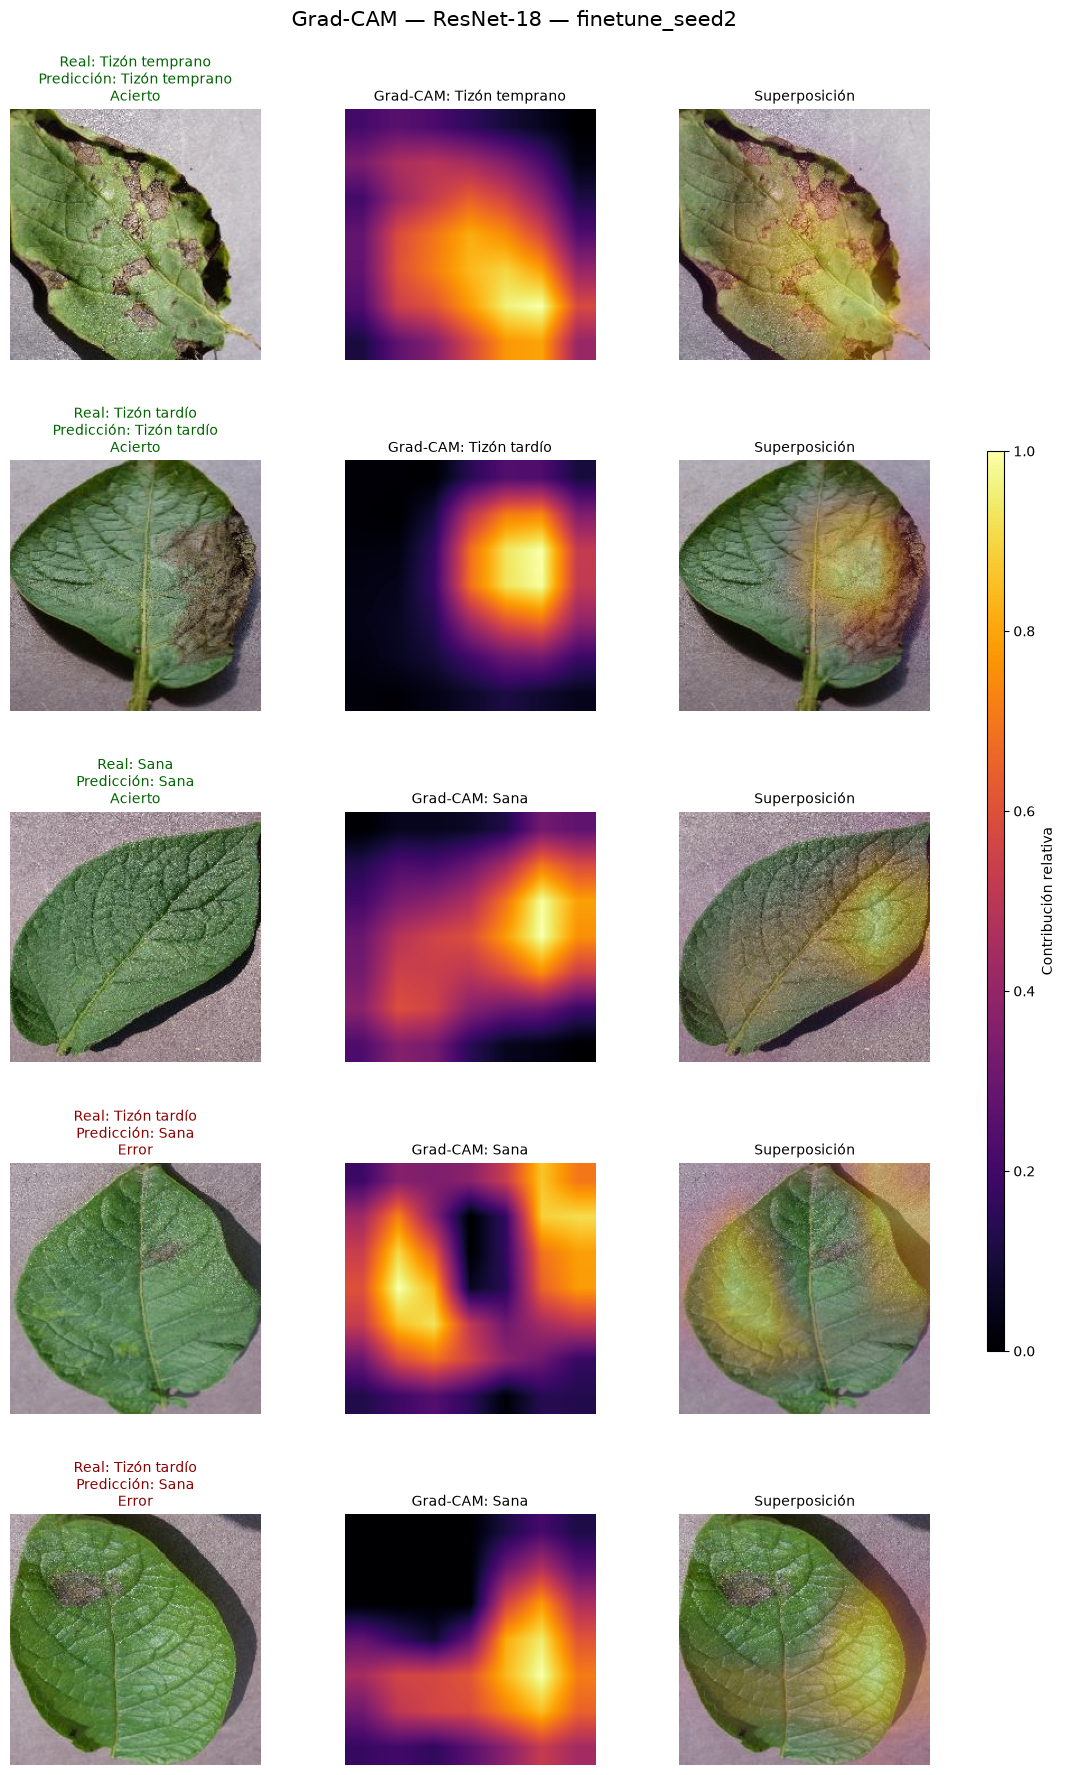

Figura guardada en: resultados\final\finetune_seed2\gradcam\gradcam_examples.png
Imágenes individuales y registro guardados en: resultados\final\finetune_seed2\gradcam


In [49]:
# Recuperamos exactamente los ejemplos utilizados en 5.15.
with (carpeta_demo / "demo_cases.csv").open(
    newline="", encoding="utf-8"
) as archivo:
    casos_gradcam = list(csv.DictReader(archivo))

assert len(casos_gradcam) > 0
assert checkpoint_gradcam["config"]["strategy"] == seleccion["strategy"]
assert checkpoint_gradcam["config"]["seed"] == seleccion["seed"]

carpeta_gradcam = carpeta_demo / "gradcam"
carpeta_gradcam.mkdir(parents=True, exist_ok=True)

# Mostramos el mismo redimensionado y recorte que recibió el modelo.
transformacion_vista = transforms.Compose(
    transformacion_eval.transforms[:2]
)

nombre_por_indice = {
    indice: clases[carpeta]
    for carpeta, indice in clase_a_indice.items()
}

cantidad_casos = len(casos_gradcam)

figura, ejes = plt.subplots(
    cantidad_casos,
    3,
    figsize=(11, 3.6 * cantidad_casos),
    squeeze=False,
)

registros_gradcam = []

for indice, registro in enumerate(casos_gradcam):
    with Image.open(registro["path"]) as imagen:
        imagen_rgb = imagen.convert("RGB")

        imagen_tensor = transformacion_eval(
            imagen_rgb
        ).unsqueeze(0)

        imagen_visible = np.asarray(
            transformacion_vista(imagen_rgb),
            dtype=np.float32,
        ) / 255.0

    clase_real = int(registro["true_label"])
    clase_objetivo = int(registro["predicted_label"])

    # Explicamos la puntuación de la clase predicha.
    mapa, prediccion_actual = generar_gradcam(
        modelo_gradcam,
        imagen_tensor,
        clase_objetivo,
    )

    # Comprobamos que la predicción en FP32 coincida con la guardada.
    assert prediccion_actual == clase_objetivo, (
        "La predicción cambió respecto a la evaluación guardada."
    )

    es_acierto = clase_real == prediccion_actual
    estado = "Acierto" if es_acierto else "Error"

    # Convertimos el mapa en colores.
    colores_calor = plt.get_cmap("inferno")(mapa)[..., :3]

    # Aplicamos más color donde la contribución es mayor.
    transparencia = 0.45 * mapa[..., None]

    superposicion = np.clip(
        (1 - transparencia) * imagen_visible
        + transparencia * colores_calor,
        0,
        1,
    )

    eje_original, eje_mapa, eje_superpuesto = ejes[indice]

    eje_original.imshow(imagen_visible)
    eje_original.set_title(
        f"Real: {nombre_por_indice[clase_real]}\n"
        f"Predicción: {nombre_por_indice[clase_objetivo]}\n"
        f"{estado}",
        fontsize=10,
        color="darkgreen" if es_acierto else "darkred",
    )

    imagen_calor = eje_mapa.imshow(
        mapa,
        cmap="inferno",
        vmin=0,
        vmax=1,
    )
    eje_mapa.set_title(
        f"Grad-CAM: {nombre_por_indice[clase_objetivo]}",
        fontsize=10,
    )

    eje_superpuesto.imshow(superposicion)
    eje_superpuesto.set_title("Superposición", fontsize=10)

    for eje in ejes[indice]:
        eje.axis("off")

    # Guardamos también las imágenes individuales para las diapositivas.
    identificador = f"case_{indice + 1:02d}"
    ruta_mapa = carpeta_gradcam / f"{identificador}_heatmap.png"
    ruta_superposicion = (
        carpeta_gradcam / f"{identificador}_overlay.png"
    )

    plt.imsave(
        ruta_mapa,
        mapa,
        cmap="inferno",
        vmin=0,
        vmax=1,
    )
    plt.imsave(ruta_superposicion, superposicion)

    registros_gradcam.append({
        "path": registro["path"],
        "leaf": registro["leaf"],
        "true_label": clase_real,
        "target_label": clase_objetivo,
        "prediction_fp32": prediccion_actual,
        "correct": int(es_acierto),
        "target_layer": "layer4.1",
        "precision": "float32",
        "map_max": float(mapa.max()),
        "heatmap": ruta_mapa.as_posix(),
        "overlay": ruta_superposicion.as_posix(),
    })

    print(
        f"Grad-CAM {indice + 1}/{cantidad_casos}: {estado} | "
        f"Clase explicada: {nombre_por_indice[clase_objetivo]}",
        flush=True,
    )

figura.suptitle(
    f"Grad-CAM — ResNet-18 — {nombre_demo}",
    fontsize=15,
    y=0.995,
)

# Reservamos espacio para los títulos y la escala de colores.
figura.subplots_adjust(
    left=0.02,
    right=0.90,
    bottom=0.02,
    top=0.94,
    hspace=0.40,
    wspace=0.12,
)

eje_barra = figura.add_axes([0.93, 0.25, 0.015, 0.50])

figura.colorbar(
    imagen_calor,
    cax=eje_barra,
    label="Contribución relativa",
)

ruta_figura = carpeta_gradcam / "gradcam_examples.png"
figura.savefig(ruta_figura, dpi=200, bbox_inches="tight")

guardar_historial(
    registros_gradcam,
    carpeta_gradcam / "gradcam_cases.csv",
)

plt.show()
plt.close(figura)

print("Figura guardada en:", ruta_figura)
print("Imágenes individuales y registro guardados en:", carpeta_gradcam)

### 5.18. Análisis de los resultados

El ajuste fino obtuvo los mejores promedios de prueba: 98.15 % de
exactitud y 0.9631 de F1 macro. También presentó menor variación
entre semillas que las otras estrategias.

La ejecución finetune_seed2 obtuvo 428 aciertos y 4 errores sobre
432 imágenes: 99.07 % de exactitud y 0.9770 de F1 macro. Se eligió
para la demostración después de observar los resultados de prueba.
La comparación conserva las nueve ejecuciones.

Sus cuatro errores fueron imágenes de tizón tardío clasificadas
como sanas y correspondieron a dos hojas distintas.

Grad-CAM muestra contribuciones positivas a la clase predicha.
En el ejemplo correcto de tizón tardío, las contribuciones se
superponen parcialmente con una zona oscura de la hoja. En el
último error, las mayores contribuciones a “Sana” aparecen hacia
la derecha, mientras la mancha visible se encuentra a la izquierda.

Estas observaciones son exploratorias. Los mapas parten de una
representación de 7 × 7 ampliada a 224 × 224; no delimitan lesiones
ni prueban una explicación causal del error.

Los resultados corresponden a la partición de PlantVillage evaluada.
Su aplicación a fotografías de campo requeriría una evaluación adicional.